# Quantum Metal 53 — the ETH Zurich 17-qubit surface-code device (Quantcore PDK rebuild)

**What the chip is.** The device of S. Krinner *et al.*, "Realizing repeated quantum error correction in a
distance-three surface code", Nature 605, 669 (2022), arXiv:2112.03708; its Table I and Methods give the targets. The
layout source is the Qiskit Metal circuit example
`docs/circuit-examples/F.Small-quantum-chips/53-Wallraff_17Qubit_SurfaceCode.ipynb` and its builder
`resources/wallraff_17q/` (© Qiskit Metal contributors, Apache-2.0, <https://github.com/qiskit-community/qiskit-metal>;
spec `docs/designs/metal/53_wallraff_17q.md`). The Metal example is a mock-up traced from the Wallraff lecture
micrographs at about 7.5 µm/px ("a mockup, not a mask"): it fixes the lattice pitch (1609.2 × 1753.9 µm), the feedline
groups and the 48 pad slots. The id is prefixed `m` (ids do not start with a digit). We distribute the rebuild under
GPL-3.0.

The device:
- 17 flux-tunable transmons: 9 data qubits D1–D9 and 8 auxiliary qubits X1–X4, Z1–Z4 on the distance-3 surface-code
  lattice. Each has an asymmetric SQUID, a flux line (shorted next to the SQUID) and a drive line.
- 24 coplanar couplers between nearest neighbours (J/2π ≈ 7 MHz at the CZ interaction point).
- Per qubit, a λ/4 readout resonator coupled to its own resonant λ/4 Purcell filter. Four feedlines read 4 or 5
  qubits each, with readouts at 6.77–7.55 GHz, about 200 MHz apart on each line.
- Data qubits idle at 3.74–4.14 GHz (α ≈ −184 MHz, g ≈ 252 MHz), auxiliary qubits at 5.89–6.33 GHz (α ≈ −170 MHz,
  g ≈ 169 MHz); κ_eff 3.5–20 MHz.

**This notebook rebuilds it with our library and the Quantcore PDK** (PDK v3, `quantcore_nb_sapphire_v1`). The
geometry comes from the surface-17 generator `examples/designs/devicelayout/_surface17.py`, which DeviceLayout's
DemoQPU17 (a demo after this device) uses too. Tutorial 03 shows both chips; here the chip is built and checked one
stage at a time, as in its Part A.

| | Metal example 53 (mock-up) and the device | Quantcore PDK rebuild |
|---|---|---|
| chip | a 14 377 µm square die traced from the micrographs, Metal's origin at D5 | the 14.4 × 14.4 mm die with the QCT frame and device ID `ETH17`, D5 at the die centre |
| substrate | the device: 150 nm Nb on high-resistivity Si (Metal: its silicon default) | sapphire 650 µm, εr 10.25 (LOM and FEM) |
| qubits | ETH's transmons with asymmetric SQUIDs (Metal: 17 `StarQubit`s, no junction drawn) | `metal:StarQubit` (180 µm radius, 5 pads) with a **Quantcore trilayer SQUID** sized for Table I |
| pads | 48 `LaunchpadWirebond` slots, 12 per edge on a 1 mm pitch (42 used: 8 feed, 17 flux, 17 drive) | a `BondPad` on each used slot, moved to **100 µm** (`frame.pad_edge`) from its edge (`edge="auto"`) |
| readout | a λ/4 readout and a resonant λ/4 Purcell filter per qubit (traced meanders), 4 feedlines | the same topology and feedline groups; our diagonal hairpin modules (the generator) |
| crossings | Metal `Airbridge`s where a line crosses an earlier one | `AirbridgeConnection`s at every crossing of the drawn lines (the generator) |
| cheese | **yes**: the Metal notebook exports its GDS with `QGDSRenderer` at its defaults (25 µm squares every 100 µm, `no_cheese.buffer` 25 µm, 200 µm edge band) | the original's Metal rule, drawn by the build (chip `cheese` = `metal_cheese_rule()`) |
| placement | D5 at the centre | centred (no shift needed) |

**Kept from the source:** the lattice and its pitch, the paper's qubit names and roles, the 24 couplers, the four
feedline groups and their order from the input pad, the pad slots along each edge with each qubit's flux and drive
pad, and Table I (idle f_q, α and f_r as targets; g, κ_eff and χ for comparison).

**Ours (the generator):** the qubit size, the diagonal hairpin readout and Purcell modules, the capacitive tees, the
series input capacitors, the control-line fan-out and the airbridges at the crossings.

**Simplified:** symmetric trilayer SQUIDs, not the paper's asymmetric ones (each data qubit's zero-flux point is set
to its idle frequency; the device idles them at the lower sweet spot); the readout–filter tap is a declared
capacitance (not drawn); no ground airbridges, and the device's flux-trap holes are not traced (Metal's cheese
stands in); the XY and Z lines end free beside the qubit and are not drive / flux controls in the LOM.

**Assumed:** the LOM-calibrated C_Σ used for the junction sizing (117 fF data, 132 fF aux) and the loading factors of
the λ/4 lengths (the plan section).

**How this notebook goes.** First the **plan** (what the source fixes, our floorplan, the junctions sized for Table I). Then the
**Design**: the chip is laid out from the plan one segment at a time, each segment its own cell with a picture of the
chip so far — the die, the 42 bond pads, the readout line (17 tees, 4 input capacitors and the four feedlines), the 17
StarQubits, their readout and Purcell λ/4s, the 24 couplers, the 34 Z / XY lines, and then the whole chip. From the v1
run: ≈ 4 min headless (`QCC_LIVE=0`) up to the FEM export, ≈ 1 min more for the optional reference; the feedback cells
(Results 4–5) add minutes. Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in one cell, with its outputs) is kept as `m53_wallraff_17q.v1.ipynb`; both save the same
`m53_wallraff_17q.json`.

## Setup

The imports, the output folder, the `REFERENCE` switch (the Reference cell after Fab also builds the Metal mock-up's
own geometry for a side-by-side picture, about a minute), `sizing_md` (the junction table of the plan) and the FEM
switches. `LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it;
with `QCC_LIVE=0` the notebook builds headless and only writes files. `_common` holds the helpers the design notebooks
share (tables, snapshots, the PDK placement, the FEM and feedback steps); `_surface17` is the surface-17 generator.

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import os, sys
from collections import Counter
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
sys.path.insert(0, str(ROOT / "examples" / "designs" / "devicelayout"))
from _common import *                            # tables, snapshots, PDK placement, FEM and feedback helpers
import _surface17 as S17                         # the surface-17 generator (shared with devicelayout/demoqpu17)
from quantcore_circuits.circuit.bridges import size_junction
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.lom.simulate import simulate
from quantcore_circuits.pdk import get_pdk

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/metal")             # this notebook's design JSON and PNG snapshots
REFERENCE = True                                 # the Reference cell: also build the mock-up's own Metal geometry (~80 s)


def sizing_md(sizing):
    """Trilayer SQUID sizing (``circuit.bridges.size_junction``, n = 2) against the PDK junction rule (as drawn)."""
    rows = ["| qubit | f_q paper (GHz) | C_Σ (fF) | L_J (nH) | R_n per junction (kΩ) | device R_n (kΩ) | "
            "drawn f_q (GHz) | R_n in 40–50 kΩ |", "|---|---|---|---|---|---|---|---|"]
    for name, s in sizing.items():
        rows.append(f"| {name} | {s.f_q_GHz:.3f} | {s.c_sigma_fF:.0f} | {s.drawn.lj_nH:.2f} | "
                    f"{s.drawn.rn_each_kohm:.1f} | {s.drawn.rn_kohm:.1f} | {s.f_q_drawn_GHz:.3f} | "
                    f"{'yes' if s.drawn.rn_in_window else 'no'} |")
    return "\n".join(rows)

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

The rebuild takes every process fact from the PDK (`get_pdk()`), not from the source: the stack the LOM and the FEM
jobs use, the die frame, where pads go, which junction is drawn, the cheese and the 3/0 keep-outs. For this chip that
means: the 14.4 mm die gets the QCT frame; the 42 bond pads go `frame.pad_edge` (100 µm) from their edges; each
StarQubit gets a trilayer SQUID; seven of the paper's nine data qubits idle below the PDK's 4–8 GHz band and no SQUID
is inside the R_n window (flagged in Check 1, not retuned); the cheese is the original's (Metal's GDS cheese), drawn by the build
instead of the PDK band.

In [4]:
display(Markdown(pdk_facts_md()))
print("pad rule: outer etch", get_pdk().frame.pad_edge, "µm from the die edge")

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

pad rule: outer etch 100.0 µm from the die edge


# Plan: what the source fixes, the floorplan, the junctions

The surface-17 generator lays the whole chip out on paper first (`S17.plan_chip`): every instance, every line's
polyline, every crossing with its airbridge. The Design segments below then place it on the chip one kind at a time.

## Plan 1 · What the source fixes: the lattice, Table I, the pad slots, the feedline groups

- **The lattice.** 17 qubits on the 5 × 5 sites `01100 / 01111 / 11111 / 11110 / 00110` (row 1 at the top), with the
  paper's names: data qubits D1–D9 where row + column is even, the auxiliary (measure) qubits X1–X4 and Z1–Z4 between
  them. Each auxiliary qubit measures the X or Z parity of its 2–4 data neighbours. `S17.neighbours` lists the 24
  couplers.
- **Table I.** Every qubit's idle frequency, anharmonicity and readout frequency (the targets), and g, κ_eff and χ
  (compared in LOM 1).
- **Pad slots.** The mock-up has 12 slots per edge on a 1 mm pitch, named by their edge and the mm from the edge centre
  (`N+2.5`, …): 8 feed pads (in and out of each feedline), 17 flux and 17 drive pads, 6 spare. `slot` turns a name into
  the pad's port position, 900 µm in from the edge (Design 2 moves the pads to the PDK edge), and the direction a line
  leaves it; `pad` names the instance (`P_Np2_5` is slot N+2.5).
- **Feedline groups.** NW {Z1, D4, Z2, D7}, NE {X1, D2, D5, X2, D1}, SE {Z4, D6, Z3, D3}, SW {X4, D8, X3, D9}, each
  listed from its input pad.

In [5]:
W = H = 14400.0                                   # the traced die is 14 377 µm; Designer = Metal + (7200, 7200)
C0, EDGE = W / 2, 900.0                           # lattice centre (D5); pad port 900 µm in from the edge
SITES = {(1, 2): "Z1", (1, 3): "D1", (2, 2): "D4", (2, 3): "X2", (2, 4): "D2", (2, 5): "X1", (3, 1): "D7",
         (3, 2): "Z2", (3, 3): "D5", (3, 4): "Z3", (3, 5): "D3", (4, 1): "X4", (4, 2): "D8", (4, 3): "X3",
         (4, 4): "D6", (5, 3): "D9", (5, 4): "Z4"}  # (row, col) of the 5 × 5 grid → paper name
GROUP = {"NW": ["Z1", "D4", "Z2", "D7"], "NE": ["X1", "D2", "D5", "X2", "D1"],
         "SE": ["Z4", "D6", "Z3", "D3"], "SW": ["X4", "D8", "X3", "D9"]}  # feedlines, from the input pad
QUAD = {q: g for g, qs in GROUP.items() for q in qs}
# Krinner et al. 2022, Table I: idle frequency (GHz), anharmonicity (MHz), readout frequency (GHz)
F_Q = {"D1": 3.885, "D2": 3.994, "D3": 3.952, "D4": 3.878, "D5": 3.895, "D6": 3.74, "D7": 4.056, "D8": 3.993,
       "D9": 4.143, "X1": 6.097, "X2": 5.885, "X3": 6.022, "X4": 6.049, "Z1": 6.328, "Z2": 6.192, "Z3": 5.956,
       "Z4": 6.037}
ALPHA = {"D1": -184, "D2": -184, "D3": -183, "D4": -184, "D5": -186, "D6": -184, "D7": -181, "D8": -183, "D9": -181,
         "X1": -170, "X2": -174, "X3": -170, "X4": -170, "Z1": -163, "Z2": -168, "Z3": -171, "Z4": -170}
F_RO = {"D1": 6.769, "D2": 6.979, "D3": 6.88, "D4": 7.12, "D5": 7.18, "D6": 7.032, "D7": 6.91, "D8": 7.075,
        "D9": 6.868, "X1": 7.372, "X2": 7.554, "X3": 7.258, "X4": 7.461, "Z1": 7.316, "Z2": 7.502, "Z3": 7.2,
        "Z4": 7.412}
# Table I values the LOM is compared with: g (MHz), κ_eff (MHz), χ (MHz)
PAPER = {"D1": (244, 6.3, -2.0), "D2": (269, 7.2, -2.2), "D3": (241, 8.3, -1.9), "D4": (241, 8.7, -1.6),
         "D5": (238, 3.5, -1.5), "D6": (244, 9.0, -1.6), "D7": (267, 8.6, -2.3), "D8": (265, 8.2, -2.0),
         "D9": (260, 8.9, -2.4), "X1": (167, 15.1, -2.8), "X2": (168, 20.1, -1.9), "X3": (167, 13.0, -3.2),
         "X4": (168, 11.0, -2.6), "Z1": (171, 11.2, -4.7), "Z2": (170, 12.2, -2.9), "Z3": (167, 14.3, -3.2),
         "Z4": (171, 10.0, -2.8)}


def slot(code):
    """Metal 53 pad slot (edge letter + mm from the edge centre, 1 mm pitch) → (x, y, port direction)."""
    e, s = code[0], float(code[1:]) * 1000.0
    return {"N": (C0 + s, H - EDGE, 270.0), "S": (C0 + s, EDGE, 90.0),
            "E": (W - EDGE, C0 + s, 180.0), "W": (EDGE, C0 + s, 0.0)}[e]


def pad(code):
    return "P_" + code.replace("+", "p").replace("-", "m").replace(".", "_")  # e.g. P_Np2_5 = slot N+2.5


FLUX_DRIVE = {"Z1": ("N-4.5", "N-2.5"), "D1": ("N+2.5", "N+0.5"), "D4": ("W+5.5", "N-5.5"), "X2": ("N+4.5", "N+3.5"),
              "D2": ("E+5.5", "N+5.5"), "X1": ("E+2.5", "E+4.5"), "D7": ("W+0.5", "W+2.5"), "Z2": ("W+3.5", "W+4.5"),
              "D5": ("E+1.5", "N-0.5"), "Z3": ("E-3.5", "E-4.5"), "D3": ("E-0.5", "E-2.5"), "X4": ("W-2.5", "W-4.5"),
              "D8": ("W-5.5", "S-5.5"), "X3": ("S-4.5", "S-3.5"), "D6": ("E-5.5", "S+5.5"), "D9": ("S-2.5", "S-0.5"),
              "Z4": ("S+4.5", "S+2.5")}  # mock-up (flux pad, drive pad)
FEED_PADS = {"NW": ("N-3.5", "W+1.5"), "NE": ("E+3.5", "N+1.5"), "SE": ("S+3.5", "E-1.5"), "SW": ("W-3.5", "S-1.5")}
PADS, CONTROLS, FEEDLINES = {}, {}, {}
for q, (fl, dr) in FLUX_DRIVE.items():
    PADS[pad(fl)], PADS[pad(dr)] = slot(fl), slot(dr)
    CONTROLS[f"Z_{q}"], CONTROLS[f"XY_{q}"] = dict(pad=pad(fl)), dict(pad=pad(dr))
for g, (pin, pout) in FEED_PADS.items():
    PADS[pad(pin)], PADS[pad(pout)] = slot(pin), slot(pout)
    FEEDLINES[g] = dict(pad_in=pad(pin), pad_out=pad(pout), qubits=GROUP[g])

grid = [[" ··· "] * 5 for _ in range(5)]
for (r, c), q in SITES.items():
    grid[r - 1][c - 1] = f" {q}{'d' if S17.is_data((r, c)) else 'a'} "
print("\n".join("".join(row) for row in grid), "\n(d = data, a = auxiliary)")
print(len(S17.neighbours(SITES)), "couplers, e.g.", S17.neighbours(SITES)[:3])
print(len(PADS), "of the 48 pad slots are used")
display(Markdown("| feedline | input pad → output pad | qubits (from the input) |\n|---|---|---|\n" + "\n".join(
    f"| {g} | `{s['pad_in']}` → `{s['pad_out']}` | {', '.join(s['qubits'])} |" for g, s in FEEDLINES.items())))

 ···  Z1a  D1d  ···  ··· 
 ···  D4d  X2a  D2d  X1a 
 D7d  Z2a  D5d  Z3a  D3d 
 X4a  D8d  X3a  D6d  ··· 
 ···  ···  D9d  Z4a  ···  
(d = data, a = auxiliary)
24 couplers, e.g. [('CPL_Z1_D1', 'Z1', 'D1'), ('CPL_Z1_D4', 'Z1', 'D4'), ('CPL_D1_X2', 'D1', 'X2')]
42 of the 48 pad slots are used


| feedline | input pad → output pad | qubits (from the input) |
|---|---|---|
| NW | `P_Nm3_5` → `P_Wp1_5` | Z1, D4, Z2, D7 |
| NE | `P_Ep3_5` → `P_Np1_5` | X1, D2, D5, X2, D1 |
| SE | `P_Sp3_5` → `P_Em1_5` | Z4, D6, Z3, D3 |
| SW | `P_Wm3_5` → `P_Sm1_5` | X4, D8, X3, D9 |

## Plan 2 · The floorplan and the plan

`S17.Config` holds what the source fixes plus our floorplan choices, and `S17.plan_chip(cfg)` lays everything out on
paper: the instances, the polyline of every line, the crossings with their airbridges, and a list of crossings it
could not bridge cleanly (too near a bend, too shallow, two bridges overlapping).

Our choices, to get near the paper's values:
- **The qubit:** a `metal:StarQubit` of 180 µm radius (centre 100 µm, coupler gap 13 µm, connector 60 µm: the SQUID
  leads stay inside the pocket), so that α alone comes out near the paper's −164 … −192 MHz. The readout-pad gap is
  20 µm on the data qubits and 40 µm on the auxiliaries, whose g is smaller in the paper.
- **Lengths:** each readout and Purcell λ/4 is v_ph/4f on the PDK stack times a loading factor calibrated once with the
  LOM (readouts × 0.95 for data and × 0.958 for aux, filters × 0.945): the qubit and the tee pull each resonance down.
  Each filter is resonant with its own readout.
- **The tap** between readout and filter is 1.2 fF (J ≈ 12 MHz); **the filter tee** is an 8-finger interdigital tee
  (κ_filter ≈ 30 MHz).
- **Pads:** `swap_pads=True` lets the generator exchange a qubit's flux and drive pads where our module layout crosses
  less; the feedlines from a top or bottom input pad enter their first tee on its far side (`enter`).
- **D5, the centre qubit,** sits in the closed plaquette X2–D2–D5–Z3: both its hairpins stay inside, its tee sits in
  the channel north of the X2–D2 coupler and the filter lead is bridged over that coupler. Its flux line comes from the
  top (pad N−0.5) through the two empty plaquettes west of X2, and its drive line from the right (E+1.5) through
  plaquette D2–X1–Z3–D3: D5's two pads are exchanged by hand.
- **D5's filter turn** `pf_u_far` is **1575 µm**. The first rebuild (2026-11-03) had 1600 µm, but the λ/4 lengths on
  the current stack are ≈ 57 µm shorter: 1600 left a 66 µm last leg that the 35 µm bend of route `PF_D5_1` cannot
  enter. (Tutorial 03 Part B uses 1575 as well.)

In [6]:
FEEDLINES["NW"]["enter"] = {"Z1": "prime_end"}    # from a top / bottom input pad: enter the first tee on its far side
FEEDLINES["SE"]["enter"] = {"Z4": "prime_end"}
FEEDLINES["NE"].update(r=30.0, stubs={"D2": (520.0, 379.0), "D5": (70.0, 70.0), "X2": (439.0, 520.0)})
# D5 sits in the closed plaquette X2–D2–D5–Z3: both hairpins inside, its tee in the channel north of the X2–D2
# coupler, the filter lead bridged over it (far turn 1575 µm); flux from the top, drive from the right (pads exchanged)
SHORT = {"D5": dict(ro_legs=5, tee=(8450.0, 9555.0), tee_rot=315.0, pf_u0=1750.0, pf_u_far=1575.0, lead_axis="x")}
CONTROLS["Z_D5"] = dict(pad=pad("N-0.5"), vias=[(6700.0, 8300.0)], u_out=1076.0)
CONTROLS["XY_D5"] = dict(pad=pad("E+1.5"), vias=[(12700.0, 7900.0)], u_out=1410.0, dv=-160.0)
STAR = {"radius": 180, "center_radius": 100, "gap_couplers": 13, "connector_length": 60,  # leads inside the pocket
        "gap_readout": (20, 40)}                  # (data, aux) readout-pad gap
CFG = S17.Config(name="m53_wallraff_17q", box=(W, H), centre=(C0, C0), pitch=(1609.2, 1753.9), labels=SITES,
                 quadrant=QUAD, f_ro=F_RO, f_q=F_Q, pads=PADS, feedlines=FEEDLINES, controls=CONTROLS,
                 shortened=SHORT, length_scale=(0.95, 0.958), pf_length_scale=0.945, swap_pads=True, star=STAR)
PLAN = S17.plan_chip(CFG)
print(S17.summary(PLAN))
print("plan problems:", PLAN["problems"] or "none")

{'instances': {'metal:StarQubit': 17, 'metal:CapNInterdigitalTee': 17, 'FingerCapacitorSquare': 4, 'BondPad': 42, 'AirbridgeConnection': 37}, 'lines': {'coupler': 24, 'resonator': 34, 'feed': 25, 'z': 17, 'xy': 17}, 'routes': 154, 'airbridges': 37, 'problems': 0}
plan problems: none


## Plan 3 · Junctions: trilayer SQUIDs sized for Table I

Every qubit is a flux-tunable `Quantcore Squid`: two trilayer junctions in parallel (fingers on 2/0 + 4/0, a 50/0
spacer with the 51–53/0 dose gradient). `circuit.bridges.size_junction(f_q, C_Σ, n=2)` sizes it for the paper's idle
frequency at the qubit's C_Σ: E_C from C_Σ, E_J from f_q, L_J from E_J, then each junction's R_n (Ambegaokar–Baratoff
with the PDK's Nb gap) and its finger area on the PDK's finger grid; the table gives the junction as drawn. C_Σ is
LOM-calibrated, 117 fF for the data qubits and 132 fF for the auxiliaries, so that the dressed f_q lands near Table I.
`trilayer_junction(..., lj_nH=..., squid=True)` turns each sizing into the StarQubit's junction parameters.

The PDK judges the device: the SQUID's parallel R_n must lie in 40–50 kΩ. The paper's data band (3.74–4.14 GHz) is
below the PDK's 4–8 GHz and its α needs a large C_Σ, so the data SQUIDs come out far above the window (80–94 kΩ)
and the auxiliaries below it (30–35 kΩ). They are flagged by the DRC (`pdk_rn`, and `pdk_fq` on the data targets
below 4 GHz), not retuned: the targets are the paper's. The finger grid also quantises the drawn data qubits: six of
the nine come out alike at 3.923 GHz.

In [7]:
C_SIGMA = {"D": 117.0, "A": 132.0}  # fF: LOM-calibrated C_Σ (data / aux) so the dressed f_q lands on Table I
SIZING = {q: size_junction(F_Q[q], C_SIGMA["D" if q.startswith("D") else "A"], n=2) for q in SITES.values()}
JJ = {q: trilayer_junction("metal:StarQubit", lj_nH=s.lj_nH, squid=True) for q, s in SIZING.items()}
print("D5 junction:", JJ["D5"])
display(Markdown(sizing_md(SIZING)))

D5 junction: ({'junction_type': 'Quantcore Squid', 'junction_params': {'lj_nH': 13.130554557123592}}, {'Lj_nH': 12.9508, 'Cj_fF': 7.8})


| qubit | f_q paper (GHz) | C_Σ (fF) | L_J (nH) | R_n per junction (kΩ) | device R_n (kΩ) | drawn f_q (GHz) | R_n in 40–50 kΩ |
|---|---|---|---|---|---|---|---|
| Z1 | 6.328 | 132 | 4.55 | 60.8 | 30.4 | 6.347 | no |
| D1 | 3.885 | 117 | 12.95 | 173.1 | 86.5 | 3.923 | no |
| D4 | 3.878 | 117 | 12.95 | 173.1 | 86.5 | 3.923 | no |
| X2 | 5.885 | 132 | 5.26 | 70.3 | 35.2 | 5.893 | no |
| D2 | 3.994 | 117 | 12.95 | 173.1 | 86.5 | 3.923 | no |
| X1 | 6.097 | 132 | 4.95 | 66.2 | 33.1 | 6.078 | no |
| D7 | 4.056 | 117 | 12.03 | 160.7 | 80.4 | 4.077 | no |
| Z2 | 6.192 | 132 | 4.81 | 64.3 | 32.1 | 6.169 | no |
| D5 | 3.895 | 117 | 12.95 | 173.1 | 86.5 | 3.923 | no |
| Z3 | 5.956 | 132 | 5.10 | 68.2 | 34.1 | 5.986 | no |
| D3 | 3.952 | 117 | 12.95 | 173.1 | 86.5 | 3.923 | no |
| X4 | 6.049 | 132 | 4.95 | 66.2 | 33.1 | 6.078 | no |
| D8 | 3.993 | 117 | 12.95 | 173.1 | 86.5 | 3.923 | no |
| X3 | 6.022 | 132 | 5.10 | 68.2 | 34.1 | 5.986 | no |
| D6 | 3.740 | 117 | 14.03 | 187.5 | 93.8 | 3.763 | no |
| D9 | 4.143 | 117 | 12.03 | 160.7 | 80.4 | 4.077 | no |
| Z4 | 6.037 | 132 | 4.95 | 66.2 | 33.1 | 6.078 | no |

# Design: the layout, one segment at a time

The chip is built from the plan the way a designer would lay it out by hand: the die, the bond pads, the readout line,
the qubits, the readout resonators, the coupling, the control lines, and then the whole chip. Each segment is one cell
with one picture of the chip so far (and, live, KLayout redraws after every cell). Every position comes from the plan,
so the order of the segments changes nothing in the drawing: `add(names)` places plan instances, `add_lines(kinds)` the
planned lines of some kinds with their airbridges, and `placed_for(kinds)` first checks that everything those lines
start or end on is on the chip (`S17.needs`, from the plan's own port references).

| segment | what is placed here |
|---|---|
| 1 | the 14.4 × 14.4 mm die with the QCT frame and the original's cheese rule |
| 2 | the 42 bond pads (`add`, with the PDK pad rule) |
| 3 | the readout line: the 17 tees, the 4 input capacitors and the four feedlines (NW, NE, SE, SW) |
| 4 | the qubits: 17 StarQubits (9 data, 8 auxiliary) with their trilayer SQUIDs |
| 5 | the readout and Purcell λ/4 hairpins, and the declared readout–filter taps |
| 6 | the coupling: the 24 nearest-neighbour couplers |
| 7 | the control routing: the 17 Z and 17 XY lines |
| 8 | the whole chip: Table I's targets, the sim groups `D5_readout` / `D5_Z3`, centring, save |

## Design 1 · The die and its frame

`Designer(name, box=...)` opens an empty chip. The box is the die (µm): 14.4 × 14.4 mm, the mock-up's traced
14 377 µm rounded up, with the lattice centre D5 at the die centre. The PDK draws the **QCT frame** on it: L dicing
markers in the four corners (1000/0), a 3 × 3 alignment grid in each corner area (1001/0), the chip boundary (100/0)
and the device ID `ETH17` on a free edge (optional: no free edge, no ID).

**Cheese: the original's.** The Metal notebook exports its GDS with `QGDSRenderer` at its defaults (Fab 1), so the
original has cheese and it wins over the PDK band: `chip={"cheese": metal_cheese_rule()}` hands the build Metal's rule
(25 µm squares every 100 µm, 25 µm clear of every etched shape, none within 200 µm of the die edge), and the build
draws it instead of the band. (The device itself has flux-trap holes in its ground; the mock-up does not trace them.)

chip cheese rule: {'size': 25.0, 'gap': 75.0, 'rows': 1000, 'clearance': 25.0, 'edge': 200.0}


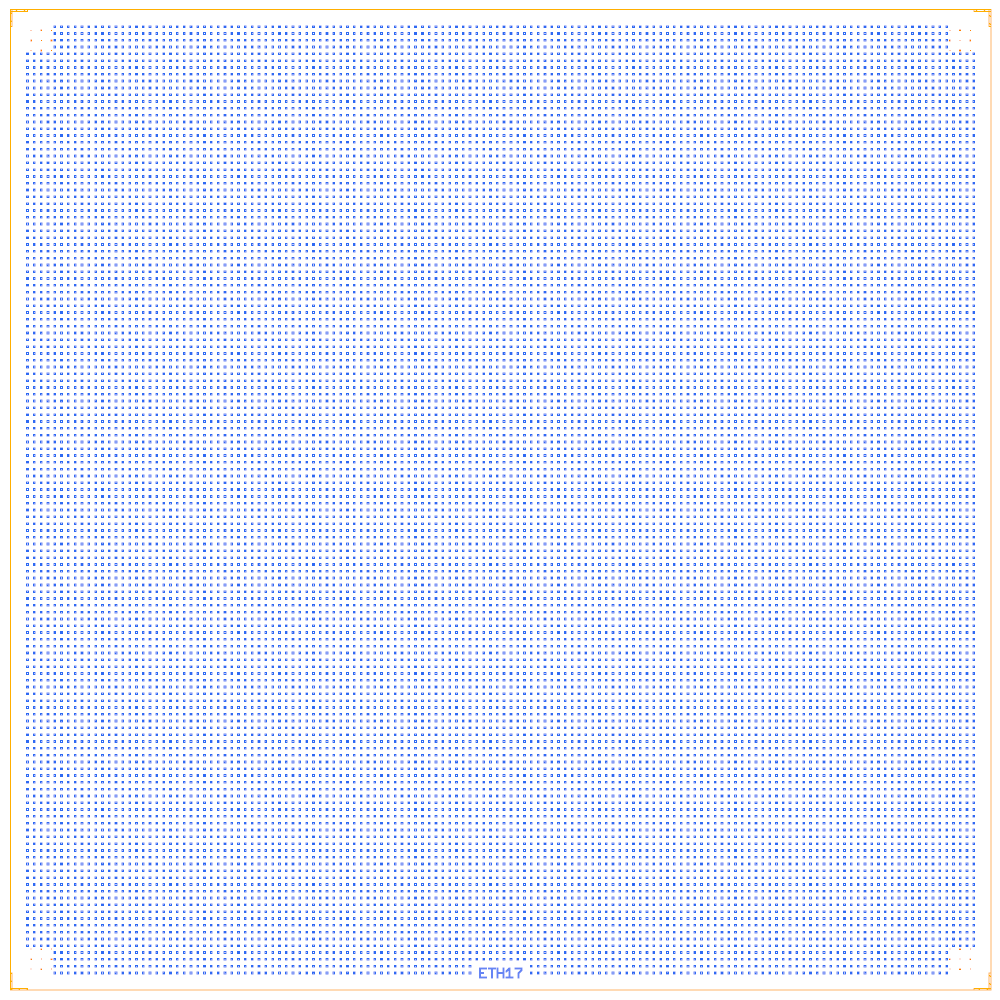

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/metal/m53_wallraff_17q_s1_die.png')

In [8]:
d = Designer("m53_wallraff_17q", box=(0, 0, W, H), chip={"name_chip": "ETH17", "cheese": metal_cheese_rule()},
             live=LIVE)
print("chip cheese rule:", d.design.chip.params["cheese"])
layout_step(d, OUT / "m53_wallraff_17q_s1_die.png", size=(1000, 1000), width=400)

## Design 2 · Bond pads: the PDK pad rule

The generator puts a `BondPad` (300 × 300 µm, 100 µm gap, 300 µm taper) on each used slot, its port 900 µm in from
the edge, so that its etch would end 200 µm from the die edge. In the Quantcore PDK the outer edge of every bond pad's
etch sits **`frame.pad_edge` = 100 µm from the die edge**, whatever the source did: `edge="auto"` slides each pad
perpendicular to its nearest edge until it is there. Its position along the edge is kept, so every line still leaves
its pad on the pad's axis and only its first straight gets longer. The table measures it on the built layout (its
first rows; the line above it counts all 42).

`add` places plan instances (qubits with their junctions, bond pads with the pad rule) in one batch; the segments below
use it for every stage.

Counter({'BondPad': 42, 'AirbridgeConnection': 37, 'metal:StarQubit': 17, 'metal:CapNInterdigitalTee': 17, 'FingerCapacitorSquare': 4})
42 of 42 pads have their etch 100.0 µm from the die edge


| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| P_Nm4_5 | `BondPad` | n | 100.0 | ✓ |
| P_Nm2_5 | `BondPad` | n | 100.0 | ✓ |
| P_Np2_5 | `BondPad` | n | 100.0 | ✓ |
| P_Np0_5 | `BondPad` | n | 100.0 | ✓ |
| P_Wp5_5 | `BondPad` | w | 100.0 | ✓ |
| P_Nm5_5 | `BondPad` | n | 100.0 | ✓ |
| … | | | | |

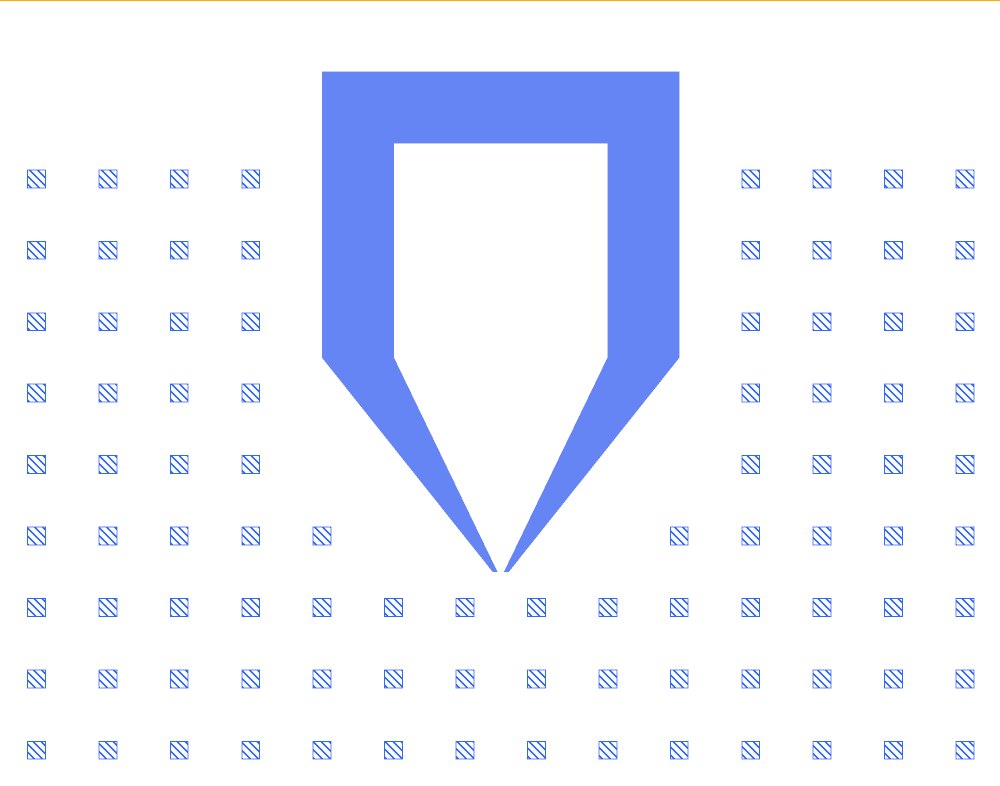

**On the chip so far:** 42 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 42 component(s) `P_Nm4_5`, `P_Nm2_5`, `P_Np2_5`, `P_Np0_5`, `P_Wp5_5`, `P_Nm5_5`, `P_Np4_5`, `P_Np3_5` … (+34).

WindowsPath('examples/designs/metal/m53_wallraff_17q_s2_pads.png')

In [9]:
INST = PLAN["instances"]


def add(names):
    """Add plan instances in one batch: qubits with their junctions, bond pads with the PDK pad rule."""
    with d.batch():
        for n in names:
            s = INST[n]
            params, jj = JJ.get(n, ({}, None))
            d.add(n, s["cell"], at=tuple(s["at"]), rot=s["rot"], **({"junction": jj} if jj else {}),
                  **({"edge": "auto"} if s["cell"] == "BondPad" else {}), **s["params"], **params)


add([n for n, s in INST.items() if s["cell"] == "BondPad"])
rebuild(d)
print(Counter(s["cell"] for s in INST.values()))
rows = pads_md(d).splitlines()
print(sum("✓" in r for r in rows[2:]), "of", len(rows) - 2, "pads have their etch", get_pdk().frame.pad_edge,
      "µm from the die edge")
display(Markdown("\n".join(rows[:8] + ["| … | | | | |"])))
px, py = port_xy(d, "P_Nm0_5.a")                 # D5's flux pad (slot N−0.5)
layout_step(d, OUT / "m53_wallraff_17q_s2_pads.png", box=(px - 700, H - 1100, px + 700, H), size=(1000, 786), width=400)

## Design 3 · Readout: the tees, the input capacitors and the four feedlines

The readout line needs no qubit, so it comes first:
- **`metal:CapNInterdigitalTee`:** the capacitive tee where a Purcell filter taps its feedline (8 fingers of 60 µm;
  κ_filter ≈ 30 MHz). `prime_start` / `prime_end` are the feedline ports, `second_end` the filter's.
- **`FingerCapacitorSquare`** (KQC): each feedline's series input capacitor (6 fingers), 700 µm from its input pad.

**Lines from the plan** (`add_lines(kinds)`): `S17.routes_of(line)` turns a planned line into qcc routes, one per
section between its airbridges, the bridges being `AirbridgeConnection` instances (`AB_<line>_<k>`) placed over the
line below. The plan has already found every crossing and decided which line passes over (couplers < resonators <
feedlines < Z < XY), and each line's airbridges come with it. So the segments can draw the kinds in a designer's
order (here the feedlines first, the lower-ranked resonators and couplers later): a bridge that carries a feedline
over a lower-ranked line is placed now, at the crossing the plan computed, and that line is drawn under it in a later
segment. `add_lines` is the v1 notebook's own helper, unchanged.

**The feedlines** (`add_lines({"feed"})`): input pad → series capacitor → each tee in order → output pad
(10/6 µm). They need the pads (Design 2), the input capacitors and the tees (this cell): `placed_for` checks it from
the plan (`S17.needs`) before drawing.

T_D5: ['prime_end', 'prime_start', 'second_end'] | CIN_NE: ['a', 'b']


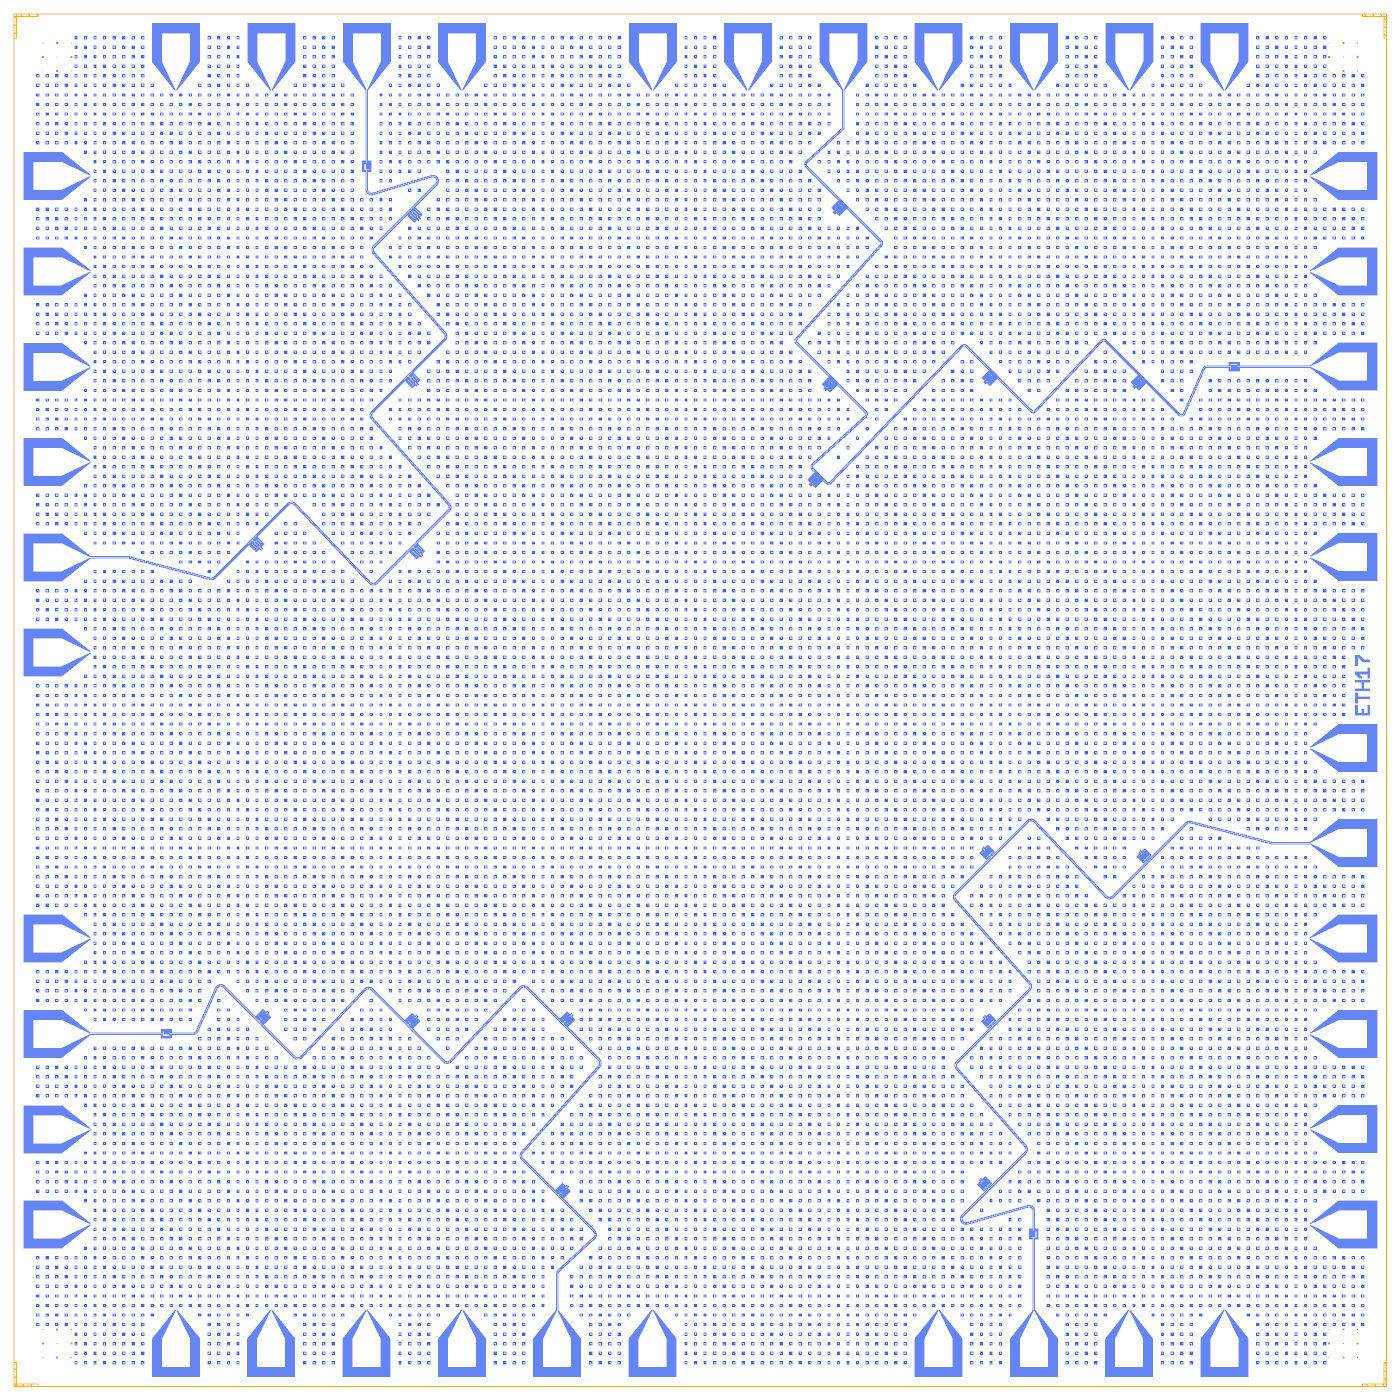

**On the chip so far:** 42 pads · 0 qubits · 21 other components · 25 routes · 0 declared couplings. **This step added** 21 component(s) `T_Z1`, `T_D1`, `T_D4`, `T_X2`, `T_D2`, `T_X1`, `T_D7`, `T_Z2` … (+13) and 25 route(s) `FLNW_in`, `FLNW_0`, `FLNW_1`, `FLNW_2`, `FLNW_3`, `FLNW_4`, `FLNE_in`, `FLNE_0` … (+17).

WindowsPath('examples/designs/metal/m53_wallraff_17q_s3_readout_line.png')

In [10]:
def add_lines(kinds):
    """Add the planned lines of these kinds: the airbridges they pass over others on, then one route per section."""
    with d.batch():
        for line in PLAN["lines"]:
            if line.kind not in kinds:
                continue
            for k in range(len(line.bridges)):
                name = f"AB_{line.name}_{k}"
                s = INST[name]
                d.add(name, s["cell"], at=tuple(s["at"]), rot=s["rot"], **s["params"])
            for r in S17.routes_of(line):
                d.route(r["name"], r["start"], r["end"], type="cpw", nodes=[tuple(n) for n in r["nodes"]],
                        a=line.a, b=line.b, r=line.r)


def placed_for(kinds):
    """Stop if a planned line of these kinds starts or ends on an instance that is not placed yet (``S17.needs``: the
    plan's own port references), so a reordered notebook fails here, with the names, and not in the router."""
    missing = S17.needs(PLAN, kinds) - set(d.data["instances"])
    assert not missing, f"the {sorted(kinds)} lines need {sorted(missing)} placed first"


add([n for n, s in INST.items() if s["cell"] in ("metal:CapNInterdigitalTee", "FingerCapacitorSquare")])
placed_for({"feed"})
add_lines({"feed"})
print("T_D5:", sorted(d["T_D5"].ports), "| CIN_NE:", sorted(d["CIN_NE"].ports))
layout_step(d, OUT / "m53_wallraff_17q_s3_readout_line.png", size=(1400, 1400), width=560)

## Design 4 · Qubit placement: 17 StarQubits

- **`metal:StarQubit`** (Quantum Metal's star transmon): a star-shaped island in a round pocket, here 180 µm in radius,
  with five pads: four couplers (`pin_cpl1` … `pin_cpl4`: E, N, W, S) and a readout pad (`pin_rdout`) on the qubit's
  readout diagonal, all pins 1.25 × the radius (225 µm) from the centre. The SQUID sits in the 90° gap between the E
  and N couplers (`squid_a` / `squid_b` are its attachment points; the cell draws it). The `rotation_*` options turn
  each qubit's readout pad and SQUID into the quadrant of its feedline, so its readout diagonal points away from the
  lattice centre.

Each gets its trilayer SQUID from the plan's sizing (Plan 3, `JJ`). The second picture zooms on the centre: D5's
plaquette.

D5 ports: ['pin_cpl1', 'pin_cpl2', 'pin_cpl3', 'pin_cpl4', 'pin_rdout', 'squid_a', 'squid_b']


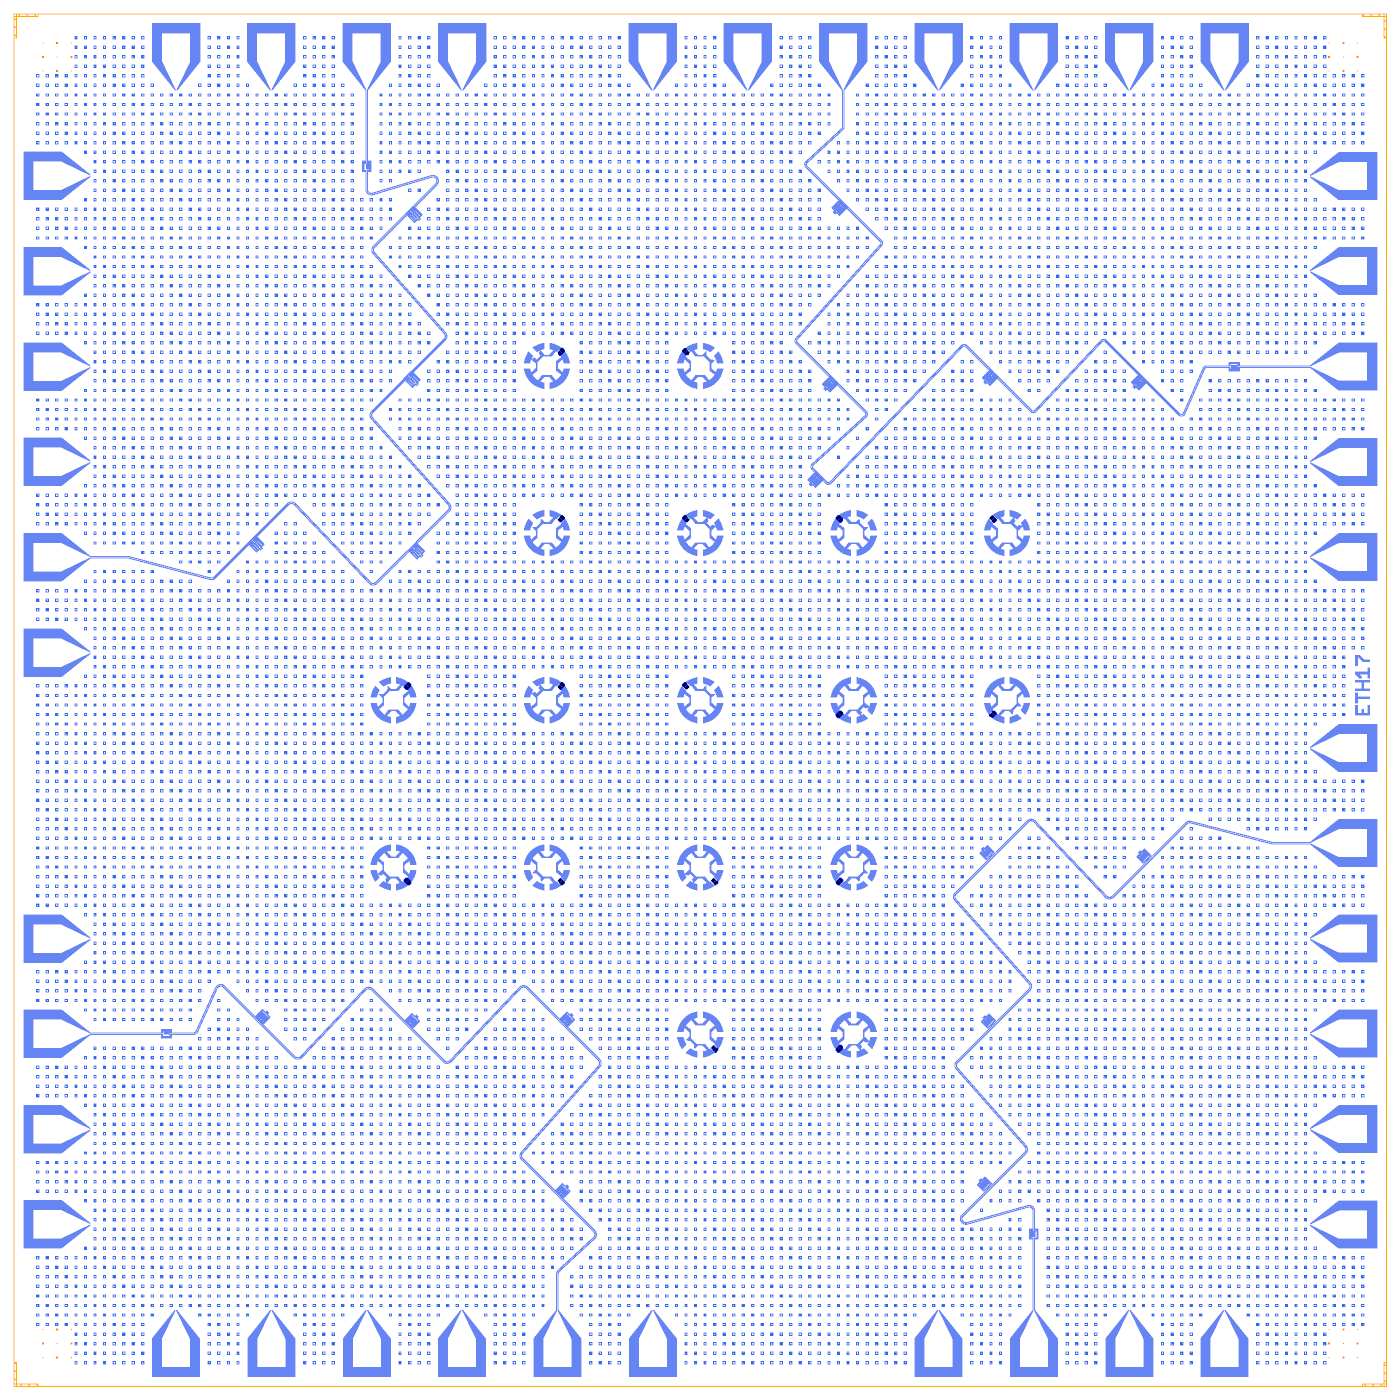

**On the chip so far:** 42 pads · 17 qubits · 21 other components · 25 routes · 0 declared couplings. **This step added** 17 component(s) `Z1`, `D1`, `D4`, `X2`, `D2`, `X1`, `D7`, `Z2` … (+9).

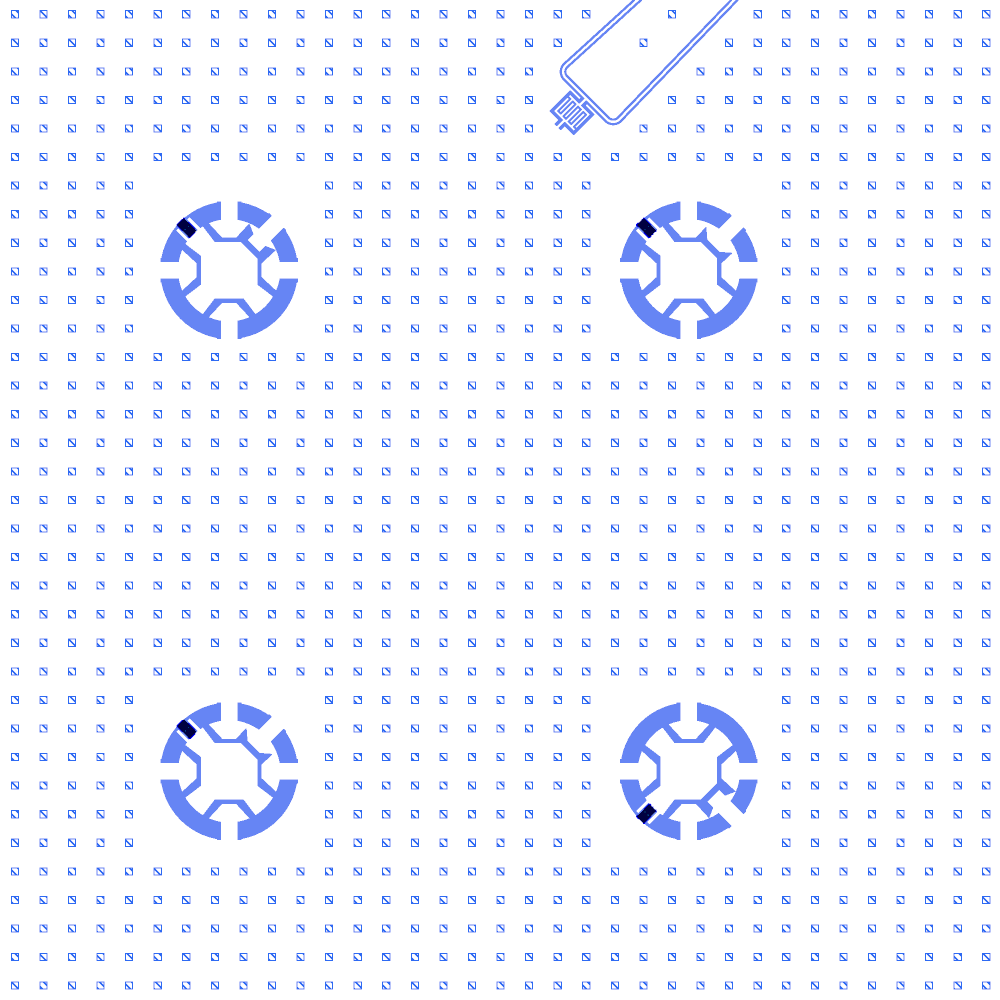

WindowsPath('examples/designs/metal/m53_wallraff_17q_step_parts.png')

In [11]:
add([n for n, s in INST.items() if s["cell"] == "metal:StarQubit"])
print("D5 ports:", sorted(d["D5"].ports))
layout_step(d, OUT / "m53_wallraff_17q_s4_qubits.png", size=(1400, 1400), width=560)
snap(d, OUT / "m53_wallraff_17q_step_parts.png", box=(C0 - 800, C0 - 800, C0 + 2700, C0 + 2700), size=(1000, 1000),
     width=420)

## Design 5 · Readout: the readout and Purcell λ/4s

**The readout modules** (`add_lines({"resonator"})`): the readout λ/4 hairpin from the readout pad,
shorted at its end, and the Purcell λ/4 hairpin from the tee's coupled port, shorted; the tap between them is a
declared capacitance (`d.couple`, 1.2 fF, not drawn). Each readout starts on its qubit's readout pad, each filter on
its tee's coupled port, so both need the qubits and the tees (`placed_for`). The second picture is the v1's
view of the whole chip with its modules.

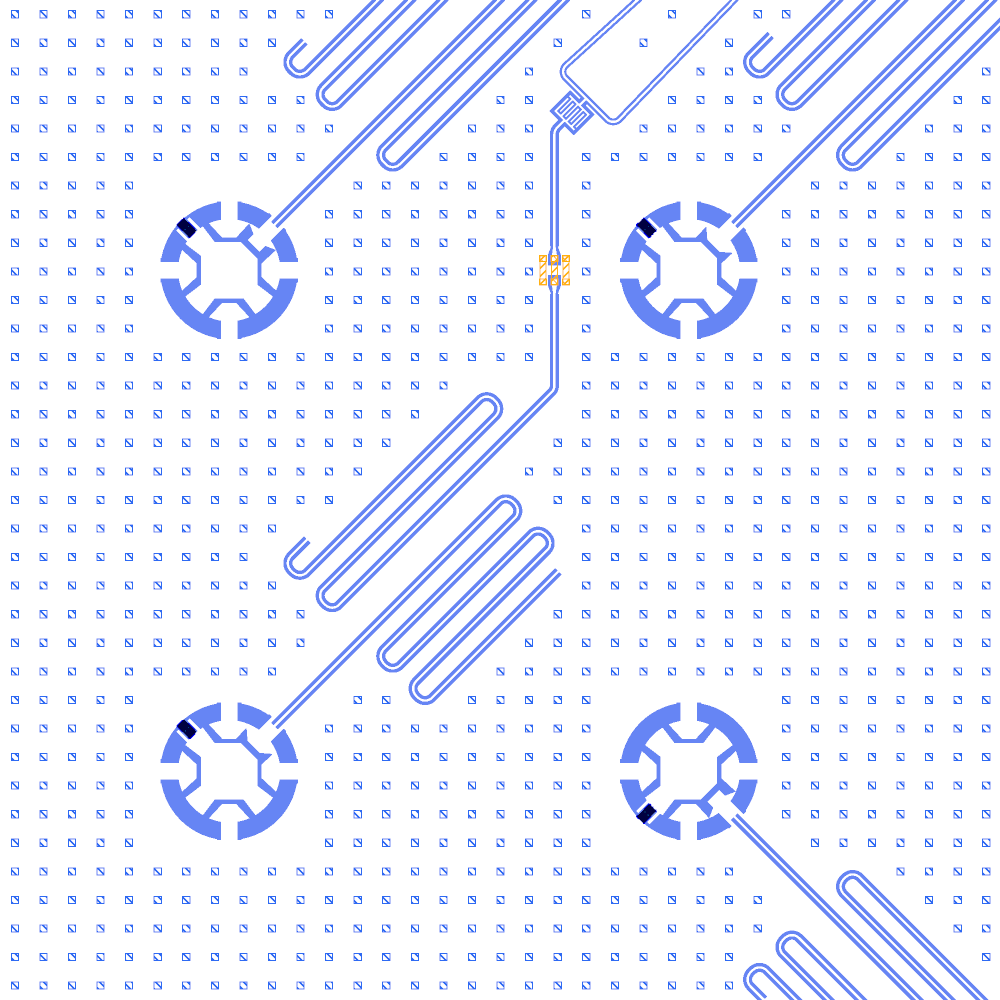

**On the chip so far:** 42 pads · 17 qubits · 22 other components · 60 routes · 17 declared couplings. **This step added** 1 component(s) `AB_PF_D5_0` and 35 route(s) `RO_Z1`, `PF_Z1`, `RO_D1`, `PF_D1`, `RO_D4`, `PF_D4`, `RO_X2`, `PF_X2` … (+27).

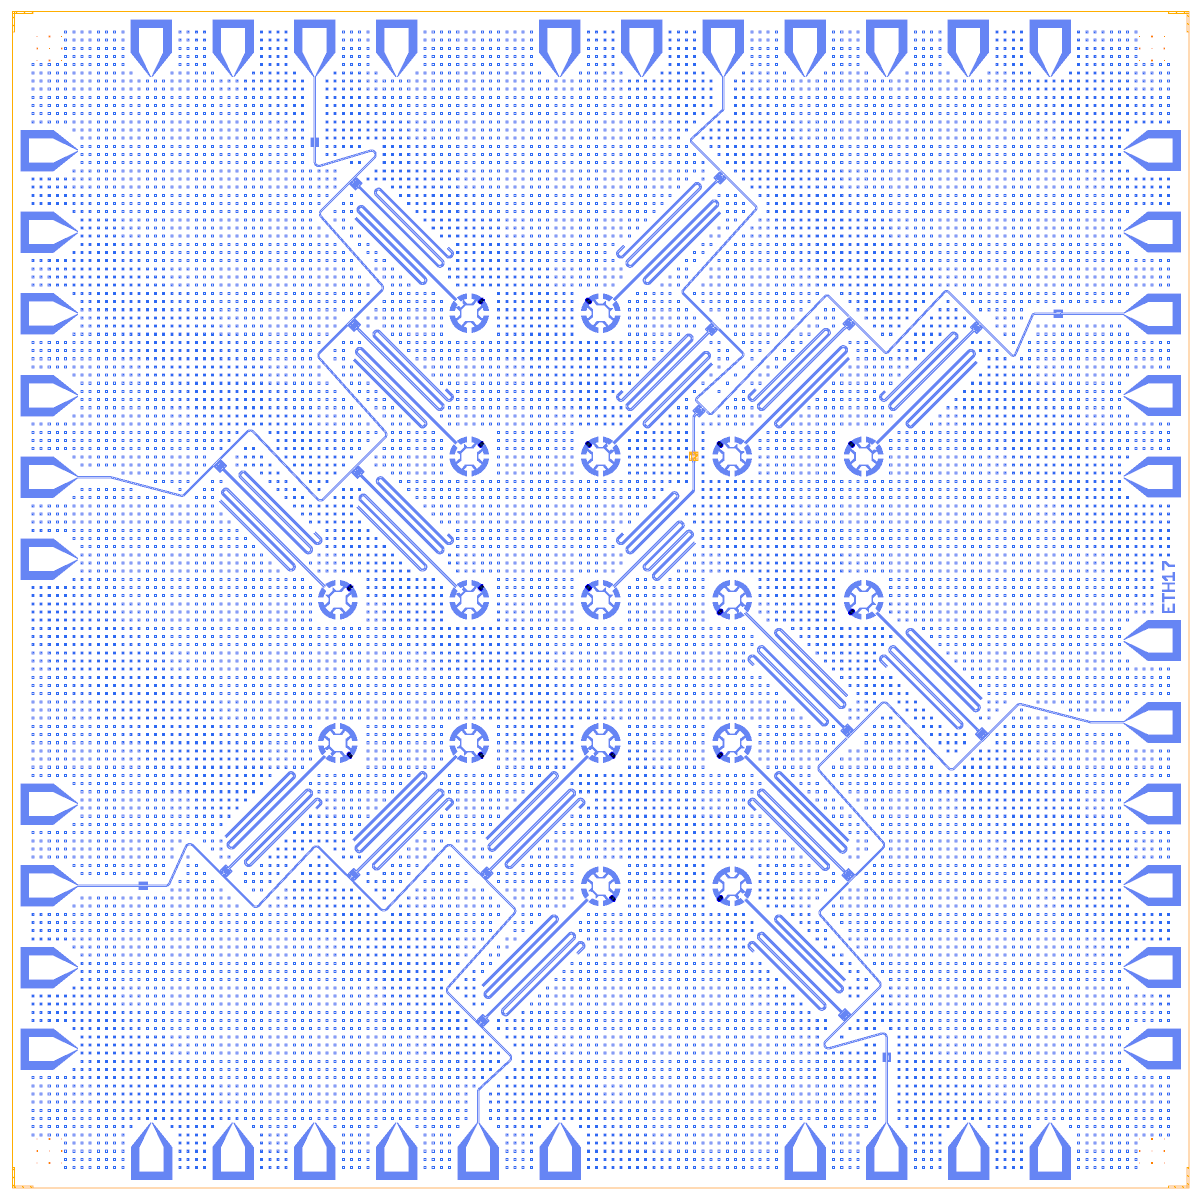

WindowsPath('examples/designs/metal/m53_wallraff_17q_step_modules.png')

In [12]:
placed_for({"resonator"})
add_lines({"resonator"})
with d.batch():
    for name, a, b, c, note in PLAN["couplings"]:  # the readout–Purcell taps: declared, not drawn
        d.couple(name, a, b, C_fF=c, note=note)
layout_step(d, OUT / "m53_wallraff_17q_s5_readouts.png", box=(C0 - 800, C0 - 800, C0 + 2700, C0 + 2700),
            size=(1000, 1000), width=420)
snap(d, OUT / "m53_wallraff_17q_step_modules.png", size=(1200, 1200), width=480)

## Design 6 · Coupling: the 24 nearest-neighbour couplers

**The couplers** (`add_lines({"coupler"})`): straight 10/10 µm CPWs between facing coupler pads. They
have the lowest rank: other lines pass over them, never the other way round. Each joins two qubits' coupler pads
(`placed_for` checks the qubits).

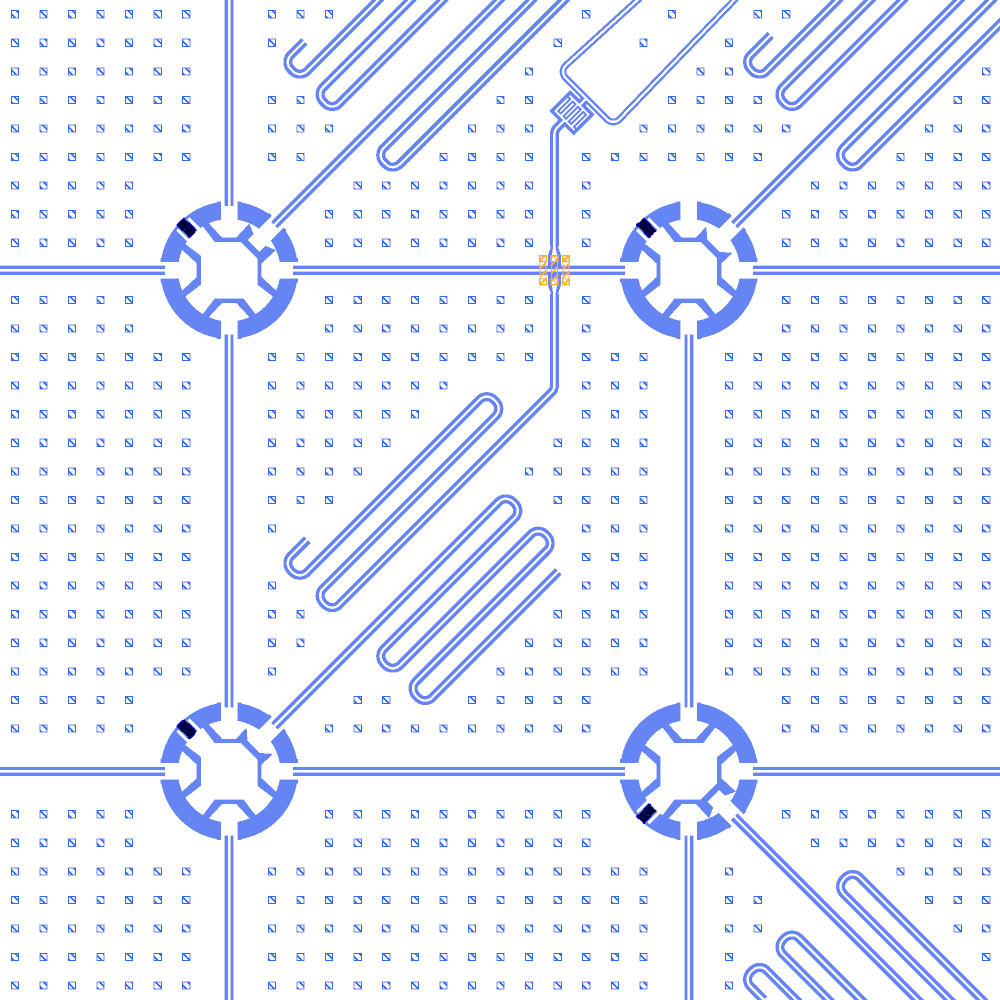

**On the chip so far:** 42 pads · 17 qubits · 22 other components · 84 routes · 17 declared couplings. **This step added** 24 route(s) `CPL_Z1_D1`, `CPL_Z1_D4`, `CPL_D1_X2`, `CPL_D4_X2`, `CPL_D4_Z2`, `CPL_X2_D2`, `CPL_X2_D5`, `CPL_D2_X1` … (+16).

WindowsPath('examples/designs/metal/m53_wallraff_17q_s6_couplers.png')

In [13]:
placed_for({"coupler"})
add_lines({"coupler"})
layout_step(d, OUT / "m53_wallraff_17q_s6_couplers.png", box=(C0 - 800, C0 - 800, C0 + 2700, C0 + 2700),
            size=(1000, 1000), width=420)

## Design 7 · Routing: the Z and XY lines

**The Z, then XY lines** (`add_lines({"z", "xy"})`): pad → a strip beside the module → the SQUID (Z,
shorted beside it, after passing over the qubit's own N coupler) or the drive end (XY, open, between the readout pad
and a coupler). They start on their pads and end free beside their qubit, so they need only the pads; their airbridges
over the feedlines, couplers and modules come with them. After this segment every planned instance and route is on the chip (the line below checks it).

117 instances, 154 routes, 37 airbridges; not placed: none


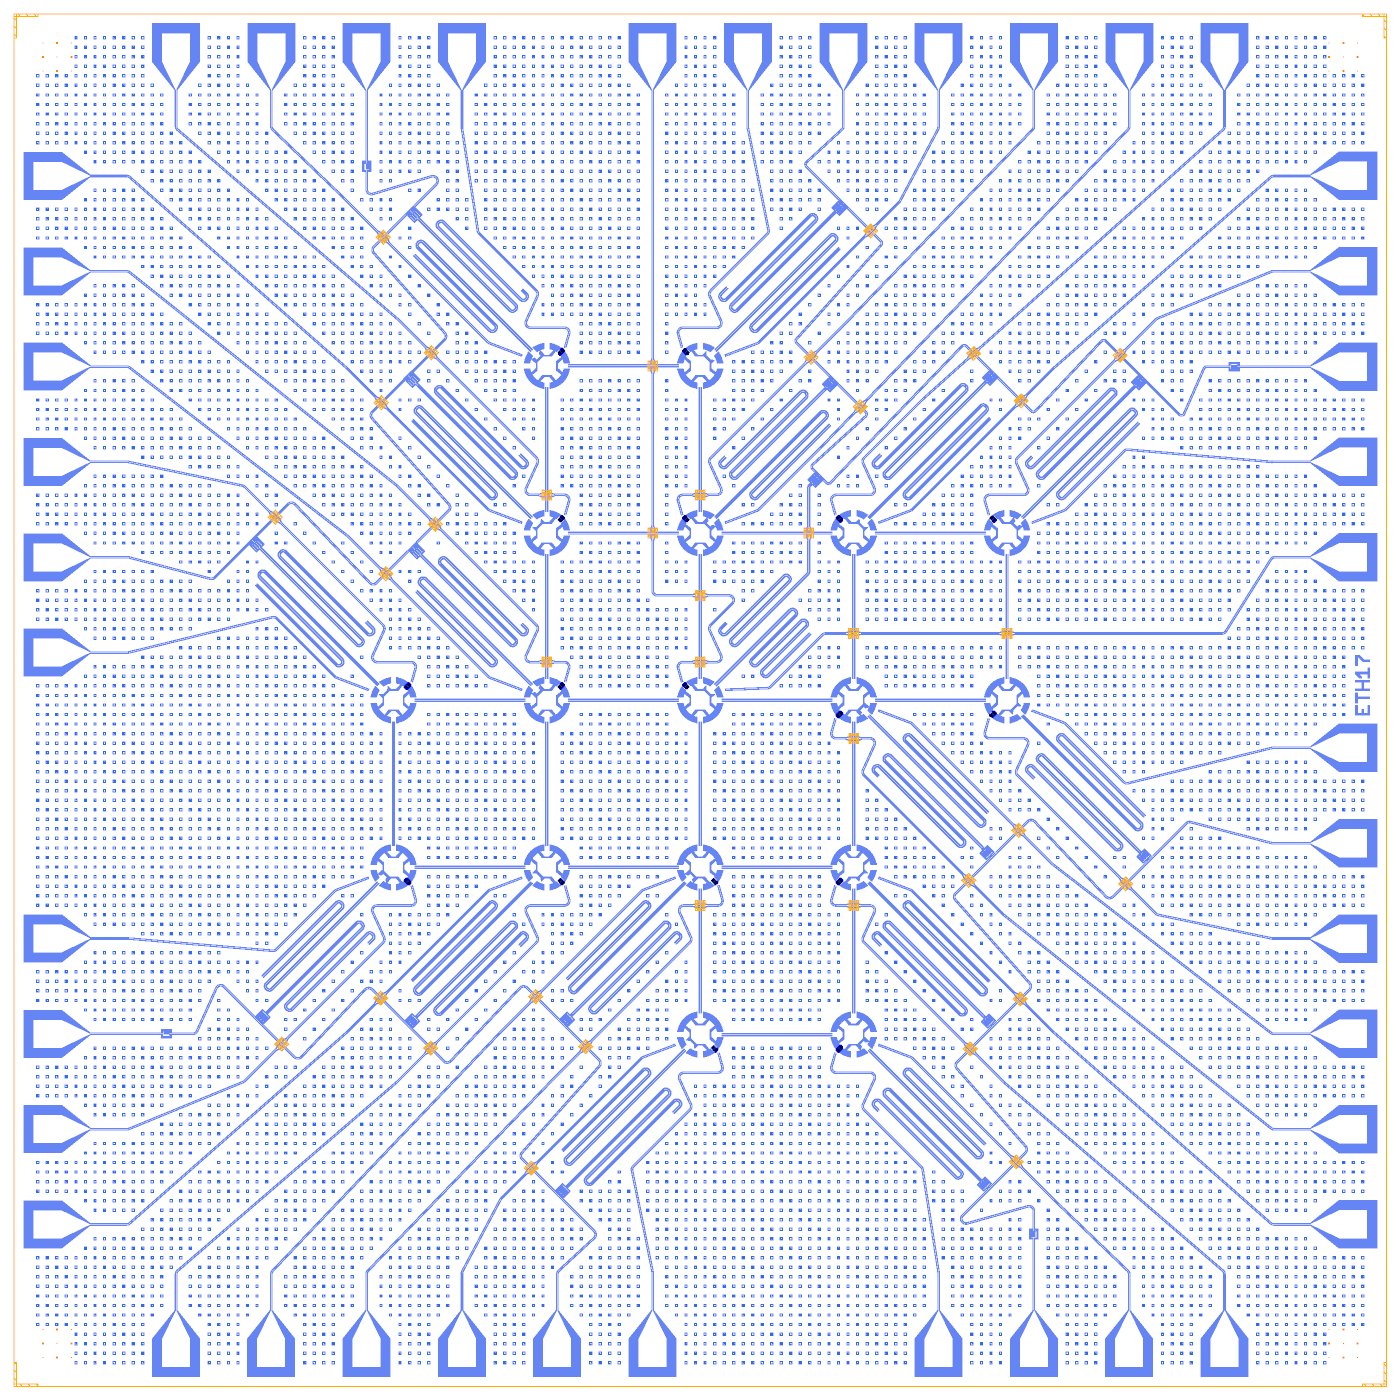

**On the chip so far:** 42 pads · 17 qubits · 58 other components · 154 routes · 17 declared couplings. **This step added** 36 component(s) `AB_XY_D1_0`, `AB_Z_D2_0`, `AB_XY_D2_0`, `AB_Z_D3_0`, `AB_Z_D4_0`, `AB_Z_D4_1`, `AB_XY_D4_0`, `AB_Z_D5_0` … (+28) and 70 route(s) `Z_D1`, `XY_D1`, `XY_D1_1`, `Z_D2`, `Z_D2_1`, `XY_D2`, `XY_D2_1`, `Z_D3` … (+62).

WindowsPath('examples/designs/metal/m53_wallraff_17q_s7_control.png')

In [14]:
placed_for({"z", "xy"})
add_lines({"z", "xy"})
missing = set(INST) - set(d.data["instances"])
print(len(d.data["instances"]), "instances,", len(d.data["routes"]), "routes,", len(PLAN["bridges"]), "airbridges;",
      "not placed:", missing or "none")
layout_step(d, OUT / "m53_wallraff_17q_s7_control.png", size=(1400, 1400), width=560)

## Design 8 · The whole chip: targets, sim groups, centring, save

- **Targets** (`d.targets`): Table I's idle f_q and α per qubit, and its readout's f_r, κ_eff and χ. The LOM tables
  show them in brackets, and the DRC's `pdk_fq` reads the f_q targets.
- **Sim groups** for the FEM jobs (Simulate 1–4). `D5_readout` is an eigenmode / EPR job of D5 with its readout hairpin, tee
  and Purcell filter, including the lead bridged over the X2–D2 coupler. It keeps that airbridge
  (`settings={"airbridges": True}`): without it the filter lead would be open at the crossing. `D5_Z3` is a Q3D
  C-matrix of D5, the auxiliary qubit Z3 and their coupler.
- **Centring.** The PDK wants the chip content centred in the die. `center_in_die` measures the bounding box of
  everything placed (components and routes) and shifts the design so its centre is the die centre (pads keep their
  100 µm: they slide back to the edge); it moves nothing when the content is within 50 µm of the centre. The lattice is
  centred on D5 and the pads sit on all four edges, so no shift is needed.

**Save.** The JSON is the deliverable. `save_design` writes it and compares it with the file it replaces (the previous
run's): the segments changed how the chip is built, not the chip, so it should say *same design*. The file keeps the
previous key order (the feedlines, readouts and couplers were added in another order here), so `git diff` stays
empty.

content shifted by (0.0, 0.0) µm


**Same design as before:** `examples/designs/metal/m53_wallraff_17q.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer m53_wallraff_17q: 117 instances, 154 routes, live=False> → examples\designs\metal\m53_wallraff_17q.json
D5's routes (µm): {'RO_D5': 4161.8, 'PF_D5': 421.4, 'PF_D5_1': 3548.6, 'CPL_X2_D5': 1303.9, 'CPL_Z2_D5': 1159.2, 'CPL_D5_Z3': 1159.2, 'CPL_D5_X3': 1303.9, 'Z_D5': 2808.8, 'Z_D5_1': 1587.1, 'Z_D5_2': 965.6, 'Z_D5_3': 1192.2, 'Z_D5_4': 344.0, 'XY_D5': 3532.0, 'XY_D5_1': 1442.4, 'XY_D5_2': 1493.3}


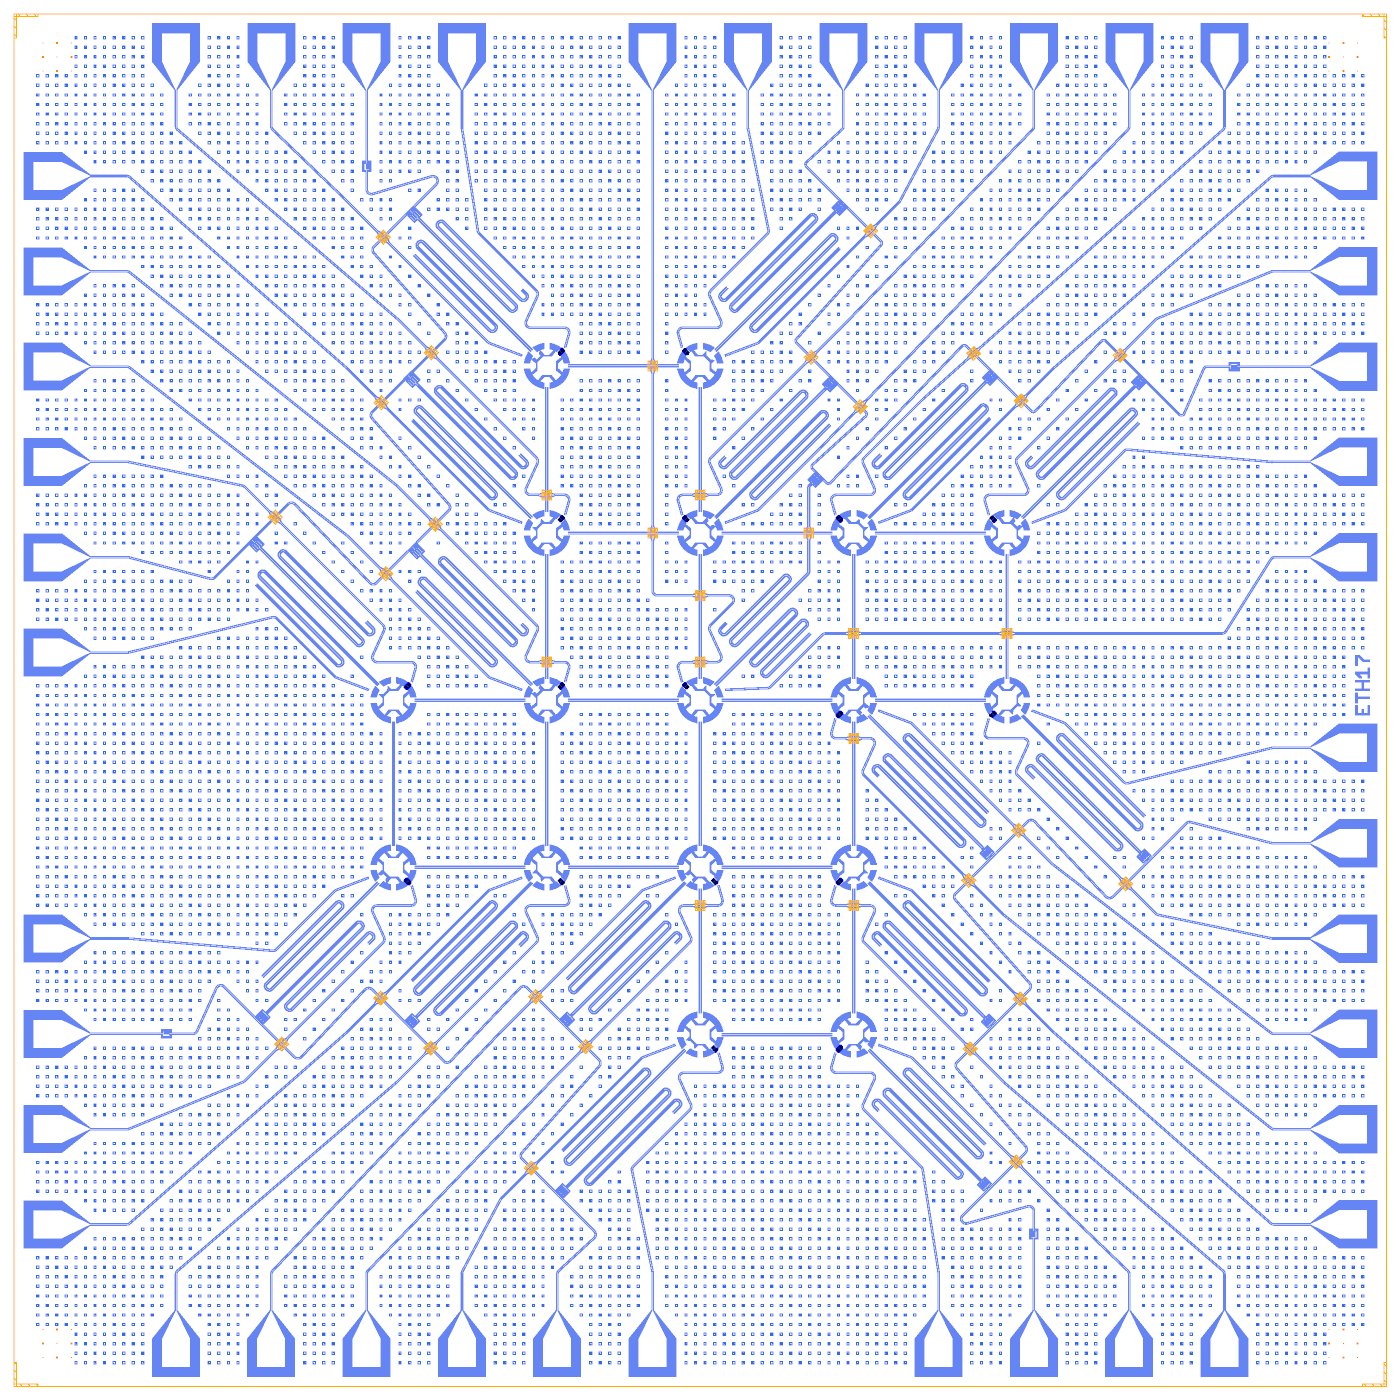

**On the chip so far:** 42 pads · 17 qubits · 58 other components · 154 routes · 17 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/metal/m53_wallraff_17q_step_routes.png')

In [15]:
with d.batch():
    d.targets(**{q: {"f_q_GHz": F_Q[q], "alpha_MHz": ALPHA[q]} for q in SITES.values()},
              **{f"RO_{q}": {"f_GHz": F_RO[q], "kappa_MHz": PAPER[q][1], "chi_MHz": PAPER[q][2]} for q in SITES.values()})
    d.sim_group("D5_readout", ["D5", "RO_D5", "T_D5", "PF_D5", "AB_PF_D5_0", "PF_D5_1"], margin_um=150,
                analyses=["eigenmode_epr"], settings={"airbridges": True})
    d.sim_group("D5_Z3", ["D5", "Z3", "CPL_D5_Z3"], margin_um=150, analyses=["q3d_cmatrix"])
shift = center_in_die(d)
rebuild(d)
print("content shifted by", shift, "µm")
DESIGN, same = save_design(d, OUT / "m53_wallraff_17q.json")
display(Markdown(same))
print(d, "→", DESIGN)
print("D5's routes (µm):", {k: round(v, 1) for k, v in d.result.route_lengths().items() if "D5" in k})
layout_step(d, OUT / "m53_wallraff_17q_step_routes.png", size=(1400, 1400), width=560)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

`d.drc()` checks connectivity (every port routed or snapped, route ends resolved), crossings, routes that loop over
themselves or run over a component, overlaps, the chip box and the frame. It has three kinds of findings:
- **errors** (open, short, crossing, outside the chip): the design is broken; there must be none;
- **warnings** (an unused port, two component boxes overlapping): worth a look, often by design;
- **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): the design is valid but leaves a PDK
  margin. They are flagged, never fixed by retuning: the values are the paper's.

Expected here (from the v1 run): **no errors**; 54 `dangling_port` warnings: 34 are the qubits' `squid_a` / `squid_b` (the junction
attachment points: the cell draws the SQUID itself, nothing is routed there) and 20 are the coupler pads of edge qubits
with no neighbour on that side (the device grounds them with airbridges; here they are left free). **24 PDK design
warnings:** `pdk_rn` on all 17 SQUIDs (data 80–94 kΩ, aux 30–35 kΩ, Plan 3) and `pdk_fq` on the seven data qubits
whose Table I idle frequency is below 4 GHz (D1–D6 and D8; D7 at 4.056 and D9 at 4.143 GHz are inside the band). No
`pad_edge` (the 42 pads sit at 100 µm), no overlaps, no route looping over itself or over a component.

`pdk_report(d)` sums up the PDK side: the cheese source, how far the content centre is from the die centre, the
junction types and the design warnings (the first twelve are listed).

In [ ]:
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist: the 17-qubit node structure

`d.lom()` turns the layout into a lumped circuit:
- each `StarQubit` → a grounded island with its SQUID, plus a node per pad;
- each coupler → a wire joining two coupler pads into one node (C_g – node – C_g between the two islands);
- each readout and each filter → a λ/4 `TLres`: the readout's open end on the readout-pad node, the filter's on its
  tee's coupled node; the tee's IDC joins that node to the feedline node; `K_<q>` is the readout–filter tap;
- each feedline → one node carrying its tees, with a 50 Ω port behind its series input capacitor and one at its output
  pad;
- the XY and Z lines → stubs on their pads (no drive or flux control: `StarQubit` has no drive or flux port).

The table gives each qubit's feedline group, its neighbours, its two λ/4 lines (estimated frequency and open-end node)
and its feedline node. The four feedline nodes should carry 5, 4, 4 and 4 tees.

In [ ]:
lb = d.lom()
m = lb.model
print(netlist_md(lb).splitlines()[0])
print(Counter(b.type for b in m.branches.values()))


def tl(name):
    return next((b for n, b in m.branches.items() if b.type == "TLres" and n.startswith(name)), None)


rows = ["| qubit | group | coupled to | readout λ/4 (GHz) · node | Purcell λ/4 (GHz) · node | feedline node |",
        "|---|---|---|---|---|---|"]
for site, q in SITES.items():
    nb = [b if a == q else a for _, a, b in S17.neighbours(SITES) if q in (a, b)]
    ro, pf = tl(f"RO_{q}"), tl(f"PF_{q}")
    rows.append(f"| {q} | {QUAD[q]} | {', '.join(nb)} | {(ro.value or {}).get('f_GHz', 0):.3f} · `{ro.nodes[0]}` | "
                f"{(pf.value or {}).get('f_GHz', 0):.3f} · `{pf.nodes[0]}` | `{lb.port_map.get(f'T_{q}.prime_start')}` |")
display(Markdown("\n".join(rows)))
feeds = Counter(lb.port_map.get(f"T_{q}.prime_start") for q in SITES.values())
print("tees per feedline node:", dict(feeds))

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation against Table I

Each qubit is simulated with its readout chain (readout λ/4, tap, Purcell λ/4, tee and the airbridges on them) and
its **whole feedline** (all its tees, the input capacitor, both 50 Ω ports), so that κ is the decay through the filter
into the line: QuCat normal modes, QuTiP dressed values, Table I in brackets. The second table compares g, κ_eff and χ
with Table I; g is computed from the simulated χ, g² = χ·Δ(Δ + α)/α. Then D5 and Z3 with their coupler: the two
qubit modes and the static ZZ.

What the tables show (from the v1 run):
- **Frequencies.** The readouts land within 0.5 % of Table I (6.766 … 7.557 GHz). The dressed auxiliary qubits are
  0.5–1.8 % below their idle frequencies (5.86–6.22 GHz) and the data qubits 2–5 % below (3.66–3.94 GHz), in three
  steps: the PDK finger grid draws six of the nine data SQUIDs alike (3.923 GHz drawn, Plan 3), D7 and D9 at 4.077 and
  D6 at 3.763 GHz.
- **Filters.** Each Purcell filter hybridises with its readout: the two modes sit 30–36 MHz apart for the data qubits
  and 36–44 MHz for the auxiliaries, and the filter-like mode has κ ≈ 24–37 MHz.
- **κ_r** through the filter: 6.6–8.3 MHz for the data qubits (paper 3.5–9.0) and 3.1–9.7 MHz for the auxiliaries
  (paper 10–20).
- **α** is −169 … −173 MHz (data) and −135 … −148 MHz (aux), 7–17 % smaller than the paper's −181 … −186 and
  −163 … −174: the dressing by the readout pulls it down, most for the auxiliaries, which sit closer to their readouts.
- **χ and g** are above the paper: χ −2.25 … −2.65 MHz for the data qubits (paper −1.5 … −2.4) and −5.8 … −13.8 MHz
  for the auxiliaries (paper −1.9 … −4.7); g from χ is 351–392 MHz (paper 238–269) and 313–339 MHz (paper 167–171).
  The StarQubit LOM gives all five pads the same arc, so the readout pad couples as strongly as a coupler pad, and the
  40 µm aux gap does not bring g down to the paper's. The FEM jobs (Simulate 2–3) calibrate it.
- **D5 + Z3:** two qubit modes 2.15 GHz apart (no hybridisation) and a static ZZ of −2.1 MHz, where the paper's
  J/2π ≈ 7 MHz would give about −8 kHz at this detuning. The LOM has no line capacitance for a pad-to-pad coupler
  route, so this coupling is far too strong (a LOM request; the `D5_Z3` C-matrix job measures it).

In [ ]:
def feed(g):
    spec = FEEDLINES[g]
    return [spec["pad_in"], spec["pad_out"], f"CIN_{g}", *[r for r in d.data["routes"] if r.startswith(f"FL{g}_")],
            *[f"T_{q}" for q in spec["qubits"]]]


def chain(q):
    return [q, *[r for r in d.data["routes"] if r.startswith((f"RO_{q}", f"PF_{q}"))],
            *[i for i in d.data["instances"] if i.startswith((f"AB_RO_{q}", f"AB_PF_{q}"))]]


def g_MHz(p, q):
    """g from the simulated χ (dispersive): g² = χ·Δ(Δ + α)/α (nan when the signs do not allow it)."""
    fq, fr, chi, a = (p.get(f"{q}.f_q_GHz"), p.get(f"RO_{q}.f_GHz"), p.get(f"RO_{q}.chi_MHz"), p.get(f"{q}.alpha_MHz"))
    if None in (fq, fr, chi, a) or chi * a <= 0:
        return float("nan")
    dlt = (fr - fq) * 1e3
    return (chi * dlt * (dlt + a) / a) ** 0.5


res = simulate_groups(d, {q: chain(q) + feed(QUAD[q]) for q in SITES.values()}, max_modes=3)
display(Markdown(groups_md(res, d.data["targets"])))
rows = ["| qubit | f_q (GHz) | f_r (GHz) | g LOM (paper) MHz | κ_r LOM (paper) MHz | χ LOM (paper) MHz |",
        "|---|---|---|---|---|---|"]
for q, r in res.items():
    p = r.params
    fq, fr, chi, kap = p.get(f"{q}.f_q_GHz"), p.get(f"RO_{q}.f_GHz"), p.get(f"RO_{q}.chi_MHz"), p.get(f"RO_{q}.kappa_MHz")
    if None in (fq, fr, chi, kap):
        rows.append(f"| {q} | – | – | – | – | – |")
        continue
    rows.append(f"| {q} | {fq:.3f} | {fr:.3f} | {g_MHz(p, q):.0f} ({PAPER[q][0]}) | {kap:.1f} ({PAPER[q][1]}) | "
                f"{chi:.2f} ({PAPER[q][2]}) |")
display(Markdown("\n".join(rows)))
pair = simulate_groups(d, {"D5+Z3": ["D5", "Z3", "CPL_D5_Z3"]}, max_modes=2)
display(Markdown(modes_md(pair["D5+Z3"]) + "\n\n" + zz_md(pair)))

## LOM 2 · The LOM in two plots

The same results as pictures: (a) every normal mode of each qubit's group (QuCat; circles are qubits, squares the
readout and filter modes; filled markers are the QuTiP dressed values; red bars Table I), (b) the dispersive shift |χ|
of each readout and filter mode. From the v1 run the readouts sit on their targets and each filter 30–44 MHz from its
readout, while the data qubits fall 2–5 % below theirs (the finger grid, Plan 3).

In [ ]:
plot_lom({**res, **pair}, OUT / "m53_wallraff_17q_lom.png", targets=d.data["targets"], title="m53: LOM per qubit group")

## LOM 3 · One geometry change, by hand

Before the FEM, a hand-made design step: copy the saved design (`design_copy`: a non-live Designer that never writes over the
JSON), change one property, re-run the LOM and compare. Here D5's readout-pad gap (`gap_readout`, the etched gap
between the readout pad and the island) widens from 20 to 30 µm, halfway to the auxiliary qubits' 40 µm. The pins do
not move (they sit at 1.25 × the pocket radius), so every route stays where it is; the DRC line checks it.

Result (from the v1 run): f_q rises by 15 MHz (3.804 → 3.820 GHz) and α goes from −171.3 to −173.0 MHz; the readout
moves up by 50 MHz (7.155 → 7.205 GHz), past its filter (7.17 GHz); |χ| drops from 2.48 to 1.91 MHz, nearer the
paper's 1.5 MHz, and g from χ from 392 to 346 MHz. κ moves between the two hybridised modes: the readout's rises from
6.6 to 11.2 MHz and the filter's falls from 30.8 to 26.3 MHz, because the readout now sits on the other side of its
filter and the two mix more. The readout gap is the knob that takes χ toward Table I; the readout length would then
need retuning (its LOM-calibrated 0.95 factor assumed the 20 µm gap). The DRC stays clean (the same 54 warnings and 24
PDK design warnings).

In [ ]:
d2 = design_copy(DESIGN)
d2["D5"].set(gap_readout=30)
after = simulate_groups(d2, {"D5": chain("D5") + feed(QUAD["D5"])}, max_modes=3)
display(Markdown(params_delta_md({"D5": res["D5"]}, after)))
print(f"g from χ: {g_MHz(res['D5'].params, 'D5'):.0f} → {g_MHz(after['D5'].params, 'D5'):.0f} MHz (paper {PAPER['D5'][0]})")
print("DRC after the change:", drc_md(d2.drc()).splitlines()[0])

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/metal/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

The LOM uses analytic capacitance estimates; a finite-element job measures them. `export_sims` cuts each sim group out
of the chip (the box set by `sim_group`), puts ports where lines leave the box and writes a job folder under
`build/jobs/`. Simulation exports never get cheese, and airbridges are dropped unless asked for: a note then flags
each crossing bridge, whose line is open at the crossing in the FEM model. `D5_readout` keeps them
(`settings={"airbridges": True}`; `build_simulation(..., airbridges=True)` and the CLI's `--airbridges` do the same):
the loop below the table shows both.

Two jobs:
- **`D5_readout`** (eigenmode / EPR): D5 with its readout hairpin, tee and Purcell filter, including the bridged lead.
  It gives f_r, κ and χ by EPR;
- **`D5_Z3`** (Q3D C-matrix): D5, Z3 and their coupler. It gives C_Σ, the pad capacitances and g (the paper's
  J/2π ≈ 7 MHz at the interaction point).

What the export reports (from the v1 run):
- `D5_Z3`: 12 ports: the two junctions, the coupler's two ends at the qubit pins (`waveguide`) and eight lines the box
  cuts (`edge`); the C-matrix nets are `D5.island`, `Z3.island` and the two XY ends inside the box.
- `D5_readout`: D5's junction port (L 12.95 nH, C 7.8 fF: the design's junction value, the one the LOM uses) and ten
  lines the box cuts, each ended in 50 Ω (`edge_lumped`). The box edge crosses four of them at about 45° (`FLNE_2`,
  `FLNE_3`, `XY_X2_1`, `Z_X2_1`). Their ports sit on the line's own axis, with the cut square to the line; the
  builder's note lists them with their angles. The box top moves out by 4 µm, so `Z_X2_1` leaves the box on a
  straight section. Every port has a polygon, so AEDT terminates every line. (Until 2026-11-18 these four ports were
  cut along the box normal and had no polygon.)
- Airbridges: with `airbridges=False` the bridge shapes in the box are dropped and the builder reports a conductor that
  no port touches (`Z_D5_3`, a Z-line section between two bridges); with `airbridges=True`, the group's setting, they
  are kept and that note is gone. Both report two point contacts patched for Q3D (KQC counts a point contact as
  connected, Q3D does not).

`FEM_FAST` (the switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. The command-line equivalent is `qcc hfss solve build/jobs/<job>`.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/metal/fem/: solved results are kept here
from quantcore_circuits.sim_tools import build_simulation

jobs = export_sims(DESIGN, ["D5_Z3"])
jobs_eig = export_sims(DESIGN, ["D5_readout"], analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))
for keep_ab in (False, True):                    # the group keeps its airbridges; without them the bridged lead is open
    s = build_simulation(DESIGN, "D5_readout", "eigenmode_epr", airbridges=keep_ab)
    print(f"airbridges={keep_ab}: geometry {s.geometry} | notes {s.notes}")

## Simulate 2 · Component simulation: the Q3D C-matrix

The capacitance of `D5_Z3`: D5's and Z3's islands against ground, each other and the XY ends inside the box (C_Σ and
the drive capacitances); the coupler enters through waveguide ports at the qubit pins. It measures the D5–Z3 coupling
the LOM overestimates (LOM 1: the pad-to-pad coupler has no line capacitance). Each net is named after its LOM node, so
the matrix goes straight into the circuit (Results 3). `fem_stage` solves the job with `RUN_FEM`, else loads its kept
results, else says that there are none.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

The `D5_readout` box in HFSS eigenmode, with its airbridge (the group's `settings`): D5's SQUID is a lumped L_J ‖ C_J
sheet, the readout hairpin, the tee and the Purcell filter are inside, and the ten lines the box cuts end in 50 Ω (the
four that leave it at 45° on their own axis, fixed 2026-11-18), so each mode's Q gives κ through the filter. pyEPR
(run inside qcc's own AEDT, never KQC's `run_pyepr_t1_estimate.py`) turns the junction's energy participation into
D5's dressed f_q, α and the readout's χ.

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run on the eigenmode's mesh settings

A driven HFSS run gives the S-parameters of the same box: the NE feedline's S21 through D5's tee, with the readout's
notch behind its Purcell filter. The library cannot hand the solved eigenmode **mesh** itself to a driven setup (no
such option yet), so `driven_from_eigenmode` does the nearest honest thing: the same sim group and box (airbridges
kept), the eigenmode job's mesh seeds, the adaptive-mesh frequency at the eigenmode's readout mode (the LOM's `RO_D5`
f_r before the eigenmode is solved) and a fast sweep around it. The two hybridised modes (readout and filter, 30–36 MHz
apart in the v1 LOM run) both fall inside the sweep.

In [ ]:
f_ro = res["D5"].params.get("RO_D5.f_GHz")                 # the LOM's readout frequency (LOM 1)
jobs_drv = driven_from_eigenmode(DESIGN, "D5_readout", jobs_eig["D5_readout"][0], keep_eig["D5_readout"], f_guess=f_ro)
keep_drv = fem_stage(jobs_drv, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
if keep_drv["D5_readout"]:
    display(Markdown(driven_md(keep_drv["D5_readout"])))

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by D5's junction participation p_J (≈ 1: the qubit; ≈ 0: the readout and the filter), with the LOM's
frequencies of D5's group (LOM 1) as dashed lines. The table below lists the modes and the pyEPR values.

In [ ]:
lom_f = {m.label: res["D5"].params.get(f"{m.label}.f_q_GHz") or res["D5"].params.get(f"{m.label}.f_GHz") or m.f_GHz
         for m in res["D5"].modes}
plot_eigenmodes(keep_eig, OUT / "m53_wallraff_17q_eigenmodes.png", lom=lom_f)
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

The eigenmode job in the LOM's terms: D5's mode is the one its junction participates in most, the readout's the
remaining mode nearest the LOM's `RO_D5` f_r; f_q and f_r are pyEPR's dressed frequencies, α and χ its Kerr terms,
κ = f/Q of the 50 Ω-terminated box (bulk-dielectric loss removed), next to Table I. The driven run adds its notch.

In [ ]:
fem_d5 = {}
if keep_eig.get("D5_readout"):
    fem_d5 = epr_values(keep_eig["D5_readout"], {"D5": "RO_D5"}, {"RO_D5": f_ro})
if keep_drv["D5_readout"]:
    fem_d5.update({f"driven {k}": v for k, v in driven_values(keep_drv["D5_readout"], "RO_D5", f_ro).items()})
TGT = {f"{i}.{q}": v for i, t in d.data["targets"].items() for q, v in t.items()}
if fem_d5:
    display(Markdown("| quantity | FEM | Table I |\n|---|---|---|\n" + "\n".join(
        f"| `{k}` | {v:.5g} | {TGT.get(k.replace('driven ', ''), '–')} |" for k, v in fem_d5.items() if k != "modes")))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would list D5's f_q and α and RO_D5's f_r, χ and κ "
          "from pyEPR next to Table I, and the S21 notch.")

## Results 3 · FEM against the LOM

Each job goes back into the sub-circuit it belongs to, not into the whole 17-qubit netlist. **LOM on the Q3D
C-matrix:** `fill` replaces the capacitance estimates of D5 + Z3 + coupler, and of D5's readout chain with its
feedline (D5's island is a net of the `D5_Z3` job), by the C-matrix values (matched by net name; the other branches
keep their estimates), and the same LOM runs again. (Tutorial 03 notes an open issue: in a C-matrix the StarQubit's
pin stubs may get no net; `fill` then keeps their estimates and says so.) **FEM directly:** D5's eigenmode values
(Results 2). The left column is the LOM on the component estimates (LOM 1).

In [ ]:
from quantcore_circuits.circuit.fill import fill

rows = []
if keep_q3d.get("D5_Z3"):
    for g, sel, lom_r in (("D5+Z3", ["D5", "Z3", "CPL_D5_Z3"], pair["D5+Z3"]), ("D5", chain("D5") + feed(QUAD["D5"]), res["D5"])):
        on_fem = simulate(fill(d.lom(select=sel).model, DESIGN, keep_q3d["D5_Z3"]), max_modes=3).params
        rows += [(f"{g}: {k}", v, on_fem.get(k), "LOM on the D5_Z3 C-matrix") for k, v in lom_r.params.items()
                 if k.startswith(("D5.", "Z3.", "RO_D5.")) and k.endswith(("f_q_GHz", "alpha_MHz", "f_GHz", "chi_MHz",
                                                                           "kappa_MHz"))]
lom_d5 = res["D5"].params
rows += [(k, lom_d5.get(k), v, "D5_readout eigenmode + pyEPR") for k, v in fem_d5.items() if k in lom_d5]
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts D5's and Z3's f_q and α and RO_D5's f_r, χ and κ of "
          "the LOM next to the LOM on the D5_Z3 C-matrix and next to the eigenmode, with the difference in %.")

## Results 4 · Feedback: one step towards Table I (one readout group)

The design carries Table I as its targets (Design 8): idle f_q and α per qubit, the readout's f_r, κ_eff and χ.
`target_copy(DESIGN, {})` writes the design with them (nothing added) to `build/m53_wallraff_17q_target.json`, and the
feedback works on that copy. **One readout group:** `loop.analyse(..., group="D5_readout")` builds the circuit of the
`D5_readout` sim group only (D5, its readout, tee and filter) and runs the estimators (QuCat, SQcircuit, scqubits,
Metal LOM) on that pair, so the step takes minutes, not the hour all 17 pairs would; the consensus picks one value per
quantity. Kept FEM results fill the circuit: the `D5_Z3` C-matrix where its nets match (D5's island) and the group's
own eigenmode job, whose pyEPR values join the estimators and whose mode Q gives the hanger's κ; without them, the LOM
estimates. `loop.feedback` anchors a surrogate on that point and proposes the knobs: D5's L_J for f_q, the StarQubit's
`center_radius` (the island knob) for α, its `gap_readout` (the coupler knob) for χ. The readout hairpin is drawn by
waypoints with no length to tune, so f_r is not a knob here (its notes say so); revision 1 is built and
netlist-checked.

**No PDK window here.** The paper's data qubits idle at 3.7–4.1 GHz with α ≈ −184 MHz, which needs a large C_Σ and an
L_J far above the 40–50 kΩ window (Plan 3: D5 at 86.5 kΩ): `pdk_lj_bounds` would pull L_J into it, i.e. D5 to
≈ 5.7 GHz, away from Table I. So the feedback runs without those bounds; the DRC keeps flagging `pdk_rn` (the targets are
the paper's). From the v1 run D5 sits 91 MHz below its 3.895 GHz and its |χ| is 2.48 MHz against 1.5 MHz: the step moves
L_J down and `gap_readout` up (LOM 3 shows the second by hand).

In [ ]:
from quantcore_circuits import loop
from quantcore_circuits.assembly.drc import check

GROUP = "D5_readout"                             # one readout group (R5: the estimators on all 17 pairs take too long)
DESIGN_T = target_copy(DESIGN, {})               # the design's own targets (Table I), nothing added
BOUNDS = None                                    # no PDK R_n window: Table I needs L_J outside it (see above)
FILL = [k for k in (*keep_q3d.values(), keep_eig.get(GROUP)) if k] or None   # kept FEM: C-matrix + the group's EPR
an0 = loop.analyse(str(DESIGN_T), FILL, group=GROUP, readout=False)
display(Markdown(consensus_md(an0, only_targets=True)))
prop, rev1, rev1_build = loop.feedback(an0, design_source=str(DESIGN_T), bounds=BOUNDS)
display(Markdown(proposal_md(prop)))
now = {r.param: r.chosen for r in an0.rows}
display(Markdown(before_after_md({k: now.get(k) for k in prop.residuals}, {k: prop.predicted[k] for k in prop.residuals})))
print("revision 1:", rev1, "· DRC:", "clean" if check(rev1_build).ok else "ERRORS")

## Results 5 · Iterate to the target

The feedback cell, repeated on the same group: analyse the revision → on target? → else feed back again → the next
revision, until D5's targets are inside their tolerances or `MAX_ITER` revisions are made
(`build/m53_wallraff_17q/revisions/`). Without `RUN_FEM` each revision is judged on the LOM. With `RUN_FEM = True` each
revision's `D5_Z3` Q3D job and its `D5_readout` eigenmode job are exported and solved first (`solve_rev`), so the
loop closes on FEM values (each eigenmode solve takes AEDT minutes). The table shows each iteration's values against Table I and the knobs it moved; the plot the
residual in tolerances (on target below 1). The readout's f_r has no knob here (see above), so it may keep the loop
from "on target" even when D5 is.

In [ ]:
def solve_rev(rev, k):
    """RUN_FEM: revision k's D5_Z3 Q3D job and its D5_readout eigenmode job, exported to build/jobs/rev<k>/ and
    solved (kept in fem/rev<k>/): the C-matrix and the group's own EPR point for the next analysis."""
    jobs_k = {**export_sims(rev, ["D5_Z3"], root=f"build/jobs/rev{k}"),
              **{f"{GROUP} · eig": job for job in export_sims(rev, [GROUP], analysis="eigenmode_epr",
                                                           root=f"build/jobs/rev{k}").values()}}
    kept = fem_stage(jobs_k, RUN_FEM, KEEP / f"rev{k}", force=RESOLVE, aedt=AEDT_MODE)
    return [v for v in kept.values() if v] or None


history, last, an_last = iterate_to_target(DESIGN_T, FILL, max_iter=MAX_ITER, bounds=BOUNDS,
                                           solve=solve_rev if RUN_FEM else None, an=an0, group=GROUP)
display(Markdown(history_md(history)))
plot_iterations(history, OUT / "m53_wallraff_17q_iterate.png")
print("last design:", last, "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

The design JSON saved in Design 8 is the deliverable: `qcc build`, `qcc mask` and the KLayout plugin all read it. The fab
export writes only the PDK fab layers (1/0 etch, 3/0 keep-out, 2/0 + 4/0 junction fingers, 50–53/0 spacer, the
airbridge layers, 100/0 chip boundary, 1000/0 + 1001/0 frame markers), with corner rounding and the cheese.

**Cheese: the original wins.** Example 53 ends by exporting its chip with Metal's `QGDSRenderer`
(`gds.export_to_gds(...)`; "the renderer logs notes on cheesing"), with the cheese at its defaults: on for the main
layer (`cheese.view_in_file = {main: {1: True}}`), `cheese_0_x/y` 25 µm squares every `delta_x/y` 100 µm, none within
`edge_nocheese` 200 µm of the chip edge and `no_cheese.buffer` 25 µm clear of every etched shape. So the original *has*
cheese, and the precedence rule keeps the original's, not the PDK band. The chip carries Metal's rule as its `cheese`
parameter (Design 1: `metal_cheese_rule()` = `{size, gap, rows, clearance, edge}`), so the build draws it into KQC's
`ground_grid` layer over the free ground inside the frame's design area, clear of the 3/0 keep-outs by the buffer
(the 3/0 keep-out already adds the PDK route margin round each CPW, so the holes sit a few µm further from the etch
than in Metal). The layout, the snapshots and KLive show it, and `export_fab` / `qcc mask` keep it (`cheese source:
build`, no PDK band added). In the mask every cheese hole is on 3/0 as well as on 1/0. (To see the cheese in KLayout,
load `live.snapshot.layer_props_path()`, File → Load Layer Properties: KQC's own layer properties hide `ground grid`
132/1.)

From the v1 run: 1/0 12 572 polygons; 3/0 12 404 (the keep-outs plus every cheese hole); 2/0 and 4/0 17 each and 50–53/0
68 each (the 17 trilayer SQUIDs); 222 airbridge pads on 300/0 and 111 bridges on 301/0 (37 `AirbridgeConnection`s
of three bridges); 100/0 1, 1000/0 4, 1001/0 36. Cheese source `build`, 12 398 holes.

Command-line equivalents:
- `qcc build examples/designs/metal/m53_wallraff_17q.json` (the layout and its KLayout sidecar);
- `qcc mask examples/designs/metal/m53_wallraff_17q.json` (the fab file; `--no-cheese`, `--no-round`);
- `qcc sim build examples/designs/metal/m53_wallraff_17q.json -g D5_Z3 -a q3d_cmatrix` (one FEM job);
- `qcc hfss render examples/designs/metal/m53_wallraff_17q.json -g D5_readout -a eigenmode_epr --airbridges` (the
  eigenmode job in AEDT, airbridges kept).

In [ ]:
print("design file:", DESIGN)
CHEESE = True                                    # export_fab keeps the build's cheese (the original's rule)
display(Markdown(fab_layers_md(d, cheese=CHEESE, rounding=True)))

## Fab 2 · Snapshots

- **The full die.** Compare Fig. 1 of the paper and the mock-up of the Reference cell below: the same lattice, feedline groups and pad
  slots, the pads now at the die edge, Metal's cheese over the free ground. The modules are ours: diagonal hairpin
  pairs instead of the device's meanders.
- **The centre:** D5's plaquette, with both hairpins, the tee north of the X2–D2 coupler and the bridged flux and
  drive lines.
- **D5's trilayer SQUID** (found by its 50/0 spacer).
- **One airbridge crossing.**
- **The fab mask** round D5 and its module (1/0 etch with the Metal cheese, the 3/0 keep-out with the cheese holes,
  the junction and airbridge layers).
- **The die frame's south-west corner** (dicing L on 1000/0, alignment grid on 1001/0).

Positions are read from the design and the plan.

In [ ]:
from kqcircuits.pya_resolver import pya


def spacer_centre(d, name, half=400.0):
    """Centre of an instance's trilayer junction(s): its 50/0 spacer (``qcc_spacer``) shapes in the build."""
    r, (x, y) = rebuild(d), d.data["instances"][name]["place"]["at"]
    li = next(i for i in r.layout.layer_indexes() if r.layout.get_info(i).name == "qcc_spacer")
    it, box = r.top.begin_shapes_rec_overlapping(li, pya.DBox(x - half, y - half, x + half, y + half)), pya.DBox()
    while not it.at_end():
        box += it.shape().dbbox().transformed(it.dtrans())
        it.next()
    return box.center().x, box.center().y


DX, DY = d.data["instances"]["D5"]["place"]["at"]
JX, JY = spacer_centre(d, "D5")
AX, AY = PLAN["bridges"][0]["at"]
show_snapshot(d, OUT / "m53_wallraff_17q.png", size=(1600, 1600))
show_snapshot(d, OUT / "m53_wallraff_17q_centre.png", box=(6300, 6600, 9600, 9900), size=(1400, 1400), width=560)
show_snapshot(d, OUT / "m53_wallraff_17q_jj.png", box=(JX - 30, JY - 30, JX + 30, JY + 30), size=(800, 800), width=320)
show_snapshot(d, OUT / "m53_wallraff_17q_bridge.png", box=(AX - 120, AY - 120, AX + 120, AY + 120), size=(800, 800),
              width=320)
snap_file(Path("build") / "m53_wallraff_17q_fab.oas", OUT / "m53_wallraff_17q_cheese.png",
          box=(DX - 900, DY - 600, DX + 1800, DY + 2700), size=(1000, 1222), width=420)
show_snapshot(d, OUT / "m53_wallraff_17q_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300);

## Reference: the mock-up's own geometry (optional, not saved)

The source's builder `wallraff_17q.build()` runs in a headless Metal design, and its 348 components are placed as
`metal:<Class>` cells with their Metal options:
- the traced `PolylineCPW`s, airbridges, finger and IDC capacitors and launchpads, and its 17 StarQubits (Metal
  defaults: 10 nH, no PDK junction);
- every Metal net becomes a wire.

Metal's origin is D5 at the die centre, so this replica is placed at Metal + (7188.5, 7188.5), on its own traced
14 377 µm die without the PDK frame. It is built here only for the side-by-side snapshot
`m53_wallraff_17q_reference.png` (tutorial 03 shows it too); set `REFERENCE = False` in the setup cell to skip it.
This was the notebook's deliverable before the PDK rebuild: LOM readout 8.40 GHz on the traced 3.7 mm λ/4s, against
the paper's 7.18 GHz.

In [ ]:
if REFERENCE:
    import logging, warnings
    from quantcore_circuits.layouts.metal.geometry import template_options, PLACEMENT_OPTIONS
    os.environ["QISKIT_METAL_HEADLESS"] = "True"
    sys.dont_write_bytecode = True
    logging.disable(logging.WARNING); warnings.simplefilter("ignore")
    sys.path.insert(0, str(upstream_path("qiskit-metal",
                                         "docs/circuit-examples/F.Small-quantum-chips/resources/wallraff_17q")))
    import wallraff_17q as chip
    metal = chip.build()
    logging.disable(logging.NOTSET)

    def plain(v):
        if isinstance(v, dict):
            return {k: plain(x) for k, x in v.items()}
        if isinstance(v, (list, tuple)):
            return [plain(x) for x in v]
        return float(v) if hasattr(v, "dtype") else v

    X0 = Y0 = 7188.5
    ref = Designer("m53_wallraff_17q_reference", box=(0, 0, 14377, 14377),
                   chip={"name_chip": "Metal53", "die_frame": False, "frames_enabled": []}, live=False)
    with ref.batch():
        for name, c in metal.components.items():
            cls, p = type(c).__name__, c.parse_options()
            tmpl = template_options(cls)
            opts = {k: plain(v) for k, v in c.options.items()
                    if k not in PLACEMENT_OPTIONS and k != "chip" and plain(v) != tmpl.get(k)}
            ref.add(name, f"metal:{cls}", at=(X0 + 1000 * float(p.get("pos_x", 0)), Y0 + 1000 * float(p.get("pos_y", 0))),
                    rot=float(p.get("orientation", 0)), **opts)
        for k, (_, g) in enumerate(metal.net_info.groupby("net_id")):
            a, b = [f"{metal._components[cid].name}.{pin}" for cid, pin in zip(g.component_id, g.pin_name)]
            ref.couple(f"w{k}", a, b, wire=True)
    ref.show()
    print(ref, "(reference, not saved)")
    show_snapshot(ref, OUT / "m53_wallraff_17q_reference.png", size=(1400, 1400), width=560)

## Summary

| | |
|---|---|
| matches the source | the lattice and its pitch, the paper's names and roles, the 24 couplers, the four feedline groups and their order, the pad slots with each qubit's flux and drive pad (exchanged where our layout crosses less), Table I as targets; Metal's GDS cheese (25 µm / 100 µm, 25 µm buffer), drawn by the build and kept in the mask (12 398 holes) |
| PDK changes | the 14.4 mm Quantcore die with the QCT frame (device ID `ETH17`); sapphire stack; 42 bond pads 100 µm from the die edge (the generator's 200 µm); trilayer SQUIDs sized for Table I; content centred (no shift needed) |
| ours (generator) | the 180 µm StarQubit, the diagonal hairpin readout and Purcell modules, the capacitive tees, the input capacitors, the control-line fan-out and 37 airbridges; D5's closed-plaquette module (filter turn 1575 µm) |
| LOM vs Table I (from the v1 run) | f_r within 0.5 %; f_q 0.5–1.8 % (aux) and 2–5 % (data, the finger grid) below; filters hybridised 30–44 MHz from their readouts; κ_r 3–10 MHz (paper 3.5–20); α and the auxiliaries' κ below the paper, g and χ above it (the StarQubit's equal pad arcs) |
| LOM 3 (from the v1 run) | D5's readout gap 20 → 30 µm: \|χ\| 2.48 → 1.91 MHz, g 392 → 346 MHz, f_r +50 MHz; DRC still clean |
| PDK design warnings | 24: `pdk_rn` × 17 (no SQUID in 40–50 kΩ), `pdk_fq` × 7 (data idle frequencies below 4 GHz) |
| layout | built from the plan in segments (die, pads, tees + input capacitors + feedlines, qubits, readout and Purcell λ/4s, couplers, Z / XY lines, the whole chip); the saved JSON is the v1 notebook's |
| feedback | towards Table I on a copy, one readout group (`D5_readout`): `loop.analyse(group=)` → `loop.feedback` → revisions (no PDK R_n bounds: Table I needs L_J outside the window; LOM, FEM with `RUN_FEM`) |
| open | the FEM jobs (Q3D, eigenmode, driven) are exported, not solved (`RUN_FEM = False`); the LOM's pad-to-pad coupler has no line C (D5–Z3 ZZ −2.1 MHz in the v1 run); symmetric SQUIDs, not the device's asymmetric ones; the readout–filter tap is declared, not drawn |